# Assignment 1 – Exploratory Data Analysis (EDA)
## From Data to Understanding: NBA Player Seasons, 1996-97 to 2022-23

**Course:** Introduction to Data Science – Holon Institute of Technology (HIT)  
**Dataset:** `all_seasons.csv` (one row per player per season)

**Holon Institute of Technology (HIT) — Faculty of Computer Science**

| | |
|---|---|
| **Course** | Introduction to Data Science |
| **Lecturer** | Dr. Ori Itai |
| **Teaching assistant** | Hanit Ohayon Hadad |
| **Grader** | Dror Meirovich |
| **Assignment** | 1 — Exploratory Data Analysis (EDA) |
| **Student name** | yonatan duek |
| **ID number** | 208721738 |
| **Submission** | Individual, via Git |


### Table of contents
1. Setup
2. Dataset selection and source
3. Meta-analysis of the data
4. Data quality and completeness (missing values, duplicates, suspicious values, cardinality) + cleaning
5. Univariate analysis (numeric and categorical)
6. Correlations and relationships + graphs
7. Index analysis
8. Insights and data story
9. Bonus (time dependence, feature engineering, hypothesis tests, further research)

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.3f}".format)

DATA_PATH = Path("all_seasons.csv")
RANDOM_STATE = 42
MIN_GAMES_FOR_RELIABLE_STATS = 20  # rows with fewer games are statistically noisy (see section 4.3)

NUMERIC_COLUMNS = [
    "age", "player_height", "player_weight", "gp", "pts", "reb", "ast",
    "net_rating", "oreb_pct", "dreb_pct", "usg_pct", "ts_pct", "ast_pct",
]
PERCENTAGE_COLUMNS = ["oreb_pct", "dreb_pct", "usg_pct", "ts_pct", "ast_pct"]

print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

pandas 3.1.0 | numpy 2.5.4 | seaborn 0.13.2


## 2. Dataset selection and source (15%)

### 2.1 Requirements check
| Requirement | This dataset |
|---|---|
| Tabular data | CSV table |
| At least 1,000 rows | 12,844 rows |
| At least 10 columns | 22 columns |
| Numeric + time + categorical variables | numeric (points, rebounds, height...), time (`season`, `age`, `draft_year`), categorical (team, country, college, draft round) |

### 2.2 Source description
* **Source:** the public Kaggle dataset "NBA Players" (file `all_seasons.csv`). As far as I know it was compiled from the official NBA statistics website (`stats.nba.com`). *Please verify the exact Kaggle page, author and license before submission – the file itself contains no provenance information, and that absence is itself a finding.*
* **Original purpose of collection:** NBA statistics are collected **operationally** by the league to run games, rank players and serve fans, media and teams. The Kaggle compilation was published for public analysis and modelling.
* **Collecting entity:** the NBA (original statistics); a Kaggle contributor (aggregation into one file).
* **Domain knowledge connected to the table:**
  * One row is an *aggregated season line* of a player, not a single game. Columns such as `pts`, `reb`, `ast` are **per-game averages**, while `gp` is a count of games.
  * `usg_pct`, `ts_pct`, `ast_pct`, `oreb_pct`, `dreb_pct` are advanced metrics (usage rate, true shooting, assist/rebound shares) stored as **fractions in [0, 1]**, not percentages.
  * `net_rating` is the team point differential per 100 possessions while the player is on court.
  * Seasons differ in length (lockouts in 1998-99 and 2011-12, COVID in 2019-20 and 2020-21), which affects `gp`.

## 3. Meta-analysis of the data (15%)

### 3.1 File analysis

In [2]:
def get_file_metadata(path: Path) -> pd.Series:
    """Return basic file-system facts about the data file."""
    file_stats = path.stat()
    with path.open("rb") as file_handle:
        line_count = sum(1 for _ in file_handle)
    return pd.Series({
        "file_name": path.name,
        "size_bytes": file_stats.st_size,
        "size_mb": round(file_stats.st_size / 1024 ** 2, 2),
        "format": path.suffix.lstrip(".").upper(),
        "file_last_modified (copy on this machine)": pd.Timestamp(file_stats.st_mtime, unit="s"),
        "lines_including_header": line_count,
    })


display(get_file_metadata(DATA_PATH).to_frame("value"))
raw_df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", raw_df.shape)

,value
file_name,all_seasons.csv
size_bytes,1920482
size_mb,1.830
format,CSV
file_last_modified (copy on this machine),2026-10-29 07:18:42.170268774
lines_including_header,12845


Shape (rows, columns): (12844, 22)


**Observations**
* The file is a ~1.8 MB CSV with 12,845 lines (12,844 records + header).
* There is **no creation date or provenance metadata inside the file**; the file-system timestamp only reflects when this copy was saved. Missing provenance is itself a finding: the file cannot tell us who collected it, when, or how it was aggregated.
* **Purpose of the data:** league statistics that were produced operationally (to run and report the NBA) and were later re-packaged for public analysis.

### 3.2 Data structure

In [3]:
def build_structure_summary(df: pd.DataFrame) -> pd.DataFrame:
    """Column-level overview: dtype, non-null count, unique values, first value."""
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "n_unique": df.nunique(),
        "first_value": df.iloc[0],
    })


display(build_structure_summary(raw_df))
display(raw_df.head())

,dtype,non_null,n_unique,first_value
Unnamed: 0,int64,12844,12844,0
player_name,str,12844,2551,Randy Livingston
team_abbreviation,str,12844,36,HOU
age,float64,12844,27,22.000
player_height,float64,12844,30,193.040
player_weight,float64,12844,157,94.801
college,str,10990,356,Louisiana State
country,str,12844,82,USA
draft_year,str,12844,48,1996
draft_round,str,12844,9,2


,Unnamed: 0,player_name,team_abbreviation,age,player_height,player_weight,college,country,draft_year,draft_round,draft_number,gp,pts,reb,ast,net_rating,oreb_pct,dreb_pct,usg_pct,ts_pct,ast_pct,season
0,0,Randy Livingston,HOU,22.000,193.040,94.801,Louisiana State,USA,1996,2,42,64,3.900,1.500,2.400,0.300,0.042,0.071,0.169,0.487,0.248,1996-97
1,1,Gaylon Nickerson,WAS,28.000,190.500,86.182,Northwestern Oklahoma,USA,1994,2,34,4,3.800,1.300,0.300,8.900,0.030,0.111,0.174,0.497,0.043,1996-97
2,2,George Lynch,VAN,26.000,203.200,103.419,North Carolina,USA,1993,1,12,41,8.300,6.400,1.900,-8.200,0.106,0.185,0.175,0.512,0.125,1996-97
3,3,George McCloud,LAL,30.000,203.200,102.058,Florida State,USA,1989,1,7,64,10.200,2.800,1.700,-2.700,0.027,0.111,0.206,0.527,0.125,1996-97
4,4,George Zidek,DEN,23.000,213.360,119.748,UCLA,USA,1995,1,22,52,2.800,1.700,0.300,-14.100,0.102,0.169,0.195,0.500,0.064,1996-97


In [4]:
# Units check: heights/weights look like conversions from inches and pounds.
height_in_inches = raw_df["player_height"] / 2.54
weight_in_pounds = raw_df["player_weight"] / 0.45359237
print("Heights that are whole inches :", f"{np.isclose(height_in_inches, height_in_inches.round(), atol=0.01).mean():.1%}")
print("Weights that are whole pounds :", f"{np.isclose(weight_in_pounds, weight_in_pounds.round(), atol=0.01).mean():.1%}")
print("Percentage columns range      :")
display(raw_df[PERCENTAGE_COLUMNS].agg(["min", "max"]))
print("Is 'Unnamed: 0' identical to the row position?", bool((raw_df["Unnamed: 0"] == raw_df.index).all()))

Heights that are whole inches : 99.8%
Weights that are whole pounds : 99.8%
Percentage columns range      :


,oreb_pct,dreb_pct,usg_pct,ts_pct,ast_pct
min,0.000,0.000,0.000,0.000,0.000
max,1.000,1.000,1.000,1.500,1.000


Is 'Unnamed: 0' identical to the row position? True


**Structure – expected vs. surprising**
* 12,844 rows × 22 columns, as expected (≥ 1,000 rows, ≥ 10 columns). Each row is one **player-season**, not one game.
* `Unnamed: 0` is a leftover pandas export index, identical to the row position – it carries no information and is dropped.
* `draft_year`, `draft_round`, `draft_number` are **text** (`str`) instead of numbers because the placeholder `"Undrafted"` is stored inside numeric columns. Any code that treats them as numbers would crash or silently mis-sort.
* `season` is the text `"1996-97"`; a numeric `season_start` must be derived before any time analysis.
* `player_height` has only **30 distinct values** and 99.8 % of them are whole inches converted to centimetres (same for weight: whole pounds converted to kg, e.g. `94.800728`). The precision is therefore *false precision*: the real measurement resolution is 1 inch / 1 lb.
* The `*_pct` columns are **fractions in [0, 1]**, not percentages. `ts_pct` reaches 1.5, which is arithmetically possible but only in tiny samples (see 4.3).
* `age` is stored as a float although it is an integer.

**Column names:** snake_case and mostly readable, but cryptic without domain knowledge (`gp`, `pts`, `reb`, `ast`, `usg_pct`, `ts_pct`, `net_rating`). The set of columns tells us what the collector cared about (production and body size) and what is *absent*: **minutes played, position, player id, injuries, salary and shot-level data.**

**Discussion – research or operations?** The numbers were collected for *operations and reporting*, not for research. Expected biases: (1) **survivorship / selection** – only players who appeared in at least one game exist in the data; (2) **aggregation** – one row per player-season gives a 1-game player the same weight as an 82-game player; (3) **measurement conventions** that can change over time (see section 9.1b); (4) a **US-centric** schema (the `college` column assumes an American college path).

## 4. Data quality and completeness (20%)

### 4.1 Missing values

In [5]:
def build_missing_report(df: pd.DataFrame) -> pd.DataFrame:
    """Count and percentage of NaN cells per column (only columns with gaps)."""
    missing_count = df.isna().sum()
    report = pd.DataFrame({
        "missing_count": missing_count,
        "missing_pct": missing_count / len(df) * 100,
    })
    return report[report["missing_count"] > 0]


def count_placeholder_values(df: pd.DataFrame, columns: list, placeholder: str) -> pd.DataFrame:
    """Count 'hidden' missing values that are encoded as a text placeholder."""
    counts = pd.Series({column: int((df[column] == placeholder).sum()) for column in columns})
    return counts.to_frame("placeholder_count").assign(pct=lambda table: table["placeholder_count"] / len(df) * 100)


print("Explicit missing values (NaN):")
display(build_missing_report(raw_df))
print("Hidden missing values (the string 'Undrafted' inside draft columns):")
display(count_placeholder_values(raw_df, ["draft_year", "draft_round", "draft_number"], "Undrafted"))

Explicit missing values (NaN):


,missing_count,missing_pct
college,1854,14.435


Hidden missing values (the string 'Undrafted' inside draft columns):


,placeholder_count,pct
draft_year,2358,18.359
draft_round,2411,18.771
draft_number,2414,18.795


Chi-square test (college missing vs USA/International): chi2=4106.5, p=0.00e+00


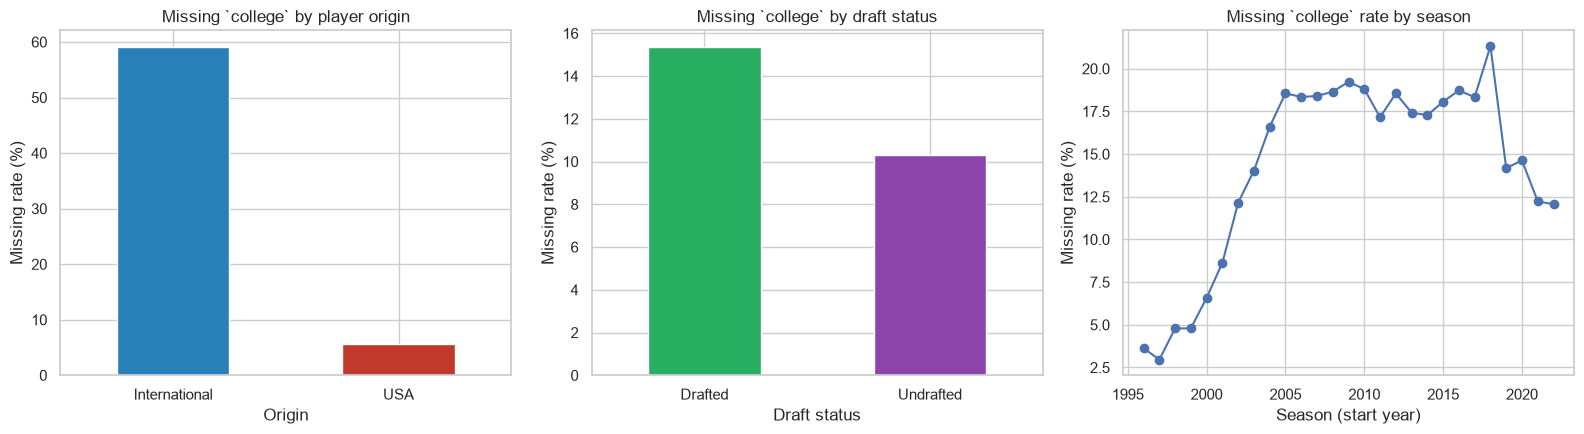

In [6]:
# Is the missingness of `college` random? Compare it across origin, draft status and time.
college_missing = raw_df["college"].isna()
origin_label = np.where(raw_df["country"].eq("USA"), "USA", "International")
draft_label = np.where(raw_df["draft_year"].eq("Undrafted"), "Undrafted", "Drafted")
season_start_raw = raw_df["season"].str[:4].astype(int)

missing_by_origin = college_missing.groupby(origin_label).mean().mul(100)
missing_by_draft = college_missing.groupby(draft_label).mean().mul(100)
missing_by_season = college_missing.groupby(season_start_raw).mean().mul(100)

contingency_table = pd.crosstab(college_missing, origin_label)
chi2_statistic, chi2_p_value, _, _ = stats.chi2_contingency(contingency_table)
print(f"Chi-square test (college missing vs USA/International): chi2={chi2_statistic:.1f}, p={chi2_p_value:.2e}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
missing_by_origin.plot.bar(ax=axes[0], color=["#2980b9", "#c0392b"], rot=0)
axes[0].set_title("Missing `college` by player origin")
axes[0].set_ylabel("Missing rate (%)")
axes[0].set_xlabel("Origin")
missing_by_draft.plot.bar(ax=axes[1], color=["#27ae60", "#8e44ad"], rot=0)
axes[1].set_title("Missing `college` by draft status")
axes[1].set_ylabel("Missing rate (%)")
axes[1].set_xlabel("Draft status")
missing_by_season.plot(ax=axes[2], marker="o")
axes[2].set_title("Missing `college` rate by season")
axes[2].set_ylabel("Missing rate (%)")
axes[2].set_xlabel("Season (start year)")
plt.tight_layout()
plt.show()

**Scope:** the only column with explicit NaNs is `college`: **1,854 rows (14.4 %)**.

**Pattern – structured, not random.**
* 59.1 % of international players have no college versus 5.6 % of US players (chi-square p ≈ 0).
* The missing rate grows from ~3.6 % in 1996-97 to roughly 17–19 % from the mid-2000s onward, mirroring the growth in international players (section 6.3).
* So "missing" mostly means **"did not play at a US college"** (international players, or US players who came straight from high school). The missingness is *informative* (missing-not-at-random by design), not an error.

**Hidden missing values.** `draft_year`, `draft_round` and `draft_number` contain `"Undrafted"` in 18.4 %, 18.8 % and 18.8 % of rows. These are not unknowns – they are a real category – but the three counts **disagree** (2,358 / 2,411 / 2,414), which already shows an inconsistent encoding (see 4.3).

**How I would fill the gaps**
* `college`: do **not** impute a school. Use an explicit label `"No US college"` plus a boolean `has_college` (done in 4.5).
* Draft columns: convert to numbers, keep NaN for undrafted and add one consistent flag `is_undrafted`. Models that cannot handle NaN can use an indicator plus a value beyond the last pick (e.g. 61).
* Numeric statistics have no missing values, so no imputation is required.

### 4.2 Duplicates

In [7]:
data_columns = [column for column in raw_df.columns if column != "Unnamed: 0"]
duplicate_definitions = {
    "Full duplicate (all columns except row id)": data_columns,
    "Partial: player_name + season": ["player_name", "season"],
    "Partial: player_name + season + team": ["player_name", "season", "team_abbreviation"],
    "Partial: player_name + season + age": ["player_name", "season", "age"],
}
duplicate_summary = pd.DataFrame({
    label: {
        "extra_rows (keep first)": int(raw_df.duplicated(subset=columns).sum()),
        "rows_involved": int(raw_df.duplicated(subset=columns, keep=False).sum()),
    }
    for label, columns in duplicate_definitions.items()
}).T
display(duplicate_summary)

same_name_same_season = raw_df[raw_df.duplicated(["player_name", "season"], keep=False)]
display(same_name_same_season[["player_name", "season", "team_abbreviation", "age", "player_height", "player_weight", "college", "gp", "pts"]])

rows_per_player = raw_df.groupby("player_name").size()
print("Seasons per player_name:")
display(rows_per_player.describe().to_frame("rows_per_player_name").T)

,extra_rows (keep first),rows_involved
Full duplicate (all columns except row id),0,0
Partial: player_name + season,4,8
Partial: player_name + season + team,0,0
Partial: player_name + season + age,0,0


,player_name,season,team_abbreviation,age,player_height,player_weight,college,gp,pts
5163,Marcus Williams,2007-08,LAC,21.000,200.660,93.894,Arizona,11,0.900
5164,Marcus Williams,2007-08,NJN,22.000,190.500,92.986,Connecticut,53,5.900
5635,Marcus Williams,2008-09,GSW,23.000,190.500,95.254,Connecticut,9,1.300
5643,Marcus Williams,2008-09,SAS,22.000,200.660,93.894,Arizona,2,2.000
7291,Chris Johnson,2012-13,MIN,27.000,210.820,95.254,Louisiana State,30,3.900
7292,Chris Johnson,2012-13,MEM,23.000,198.120,91.172,Dayton,8,3.600
7962,Tony Mitchell,2013-14,MIL,24.000,198.120,97.976,Alabama,3,2.000
7963,Tony Mitchell,2013-14,DET,22.000,203.200,106.594,North Texas,21,1.000


Seasons per player_name:


,count,mean,std,min,25%,50%,75%,max
rows_per_player_name,2551.000,5.035,4.223,1.000,2.000,4.000,8.000,22.000


**Findings**
* **Full duplicates: 0.**
* **Partial duplicates:** `(player_name, season)` appears twice for 4 pairs (8 rows). They are **different people with the same name** (different height, college and age – e.g. Marcus Williams of Arizona vs Connecticut, Chris Johnson of LSU vs Dayton, Tony Mitchell of Alabama vs North Texas). Adding `age` makes the key unique.
* A player name appears on average 5 times (max 22) – that is the **panel structure** (the same player across seasons), not duplication.

**What we can infer:** the data holds exactly one row per player per season – players who were traded appear once (see `gp > 82` in 4.3) – and `player_name` is **not** a valid identifier.

**Decision:** drop nothing. De-duplicating by name would silently delete four real player-seasons and, more dangerously, grouping by `player_name` would *merge different people*. Use the composite key `(player_name, season, age)` instead.

### 4.3 Suspicious values

In [8]:
def build_suspicious_checks(df: pd.DataFrame) -> dict:
    """Boolean masks for impossible, placeholder-like or statistically fragile values."""
    season_start = df["season"].str[:4].astype(int)
    draft_year = pd.to_numeric(df["draft_year"], errors="coerce")
    draft_round = pd.to_numeric(df["draft_round"], errors="coerce")
    draft_number = pd.to_numeric(df["draft_number"], errors="coerce")
    body_mass_index = df["player_weight"] / (df["player_height"] / 100) ** 2
    return {
        "Percentage metric outside [0, 1] (impossible)": (df[PERCENTAGE_COLUMNS].lt(0) | df[PERCENTAGE_COLUMNS].gt(1)).any(axis=1),
        "Percentage metric exactly 1.0 (suspicious cap)": df[PERCENTAGE_COLUMNS].eq(1).any(axis=1),
        "usg_pct or ts_pct exactly 0": df[["usg_pct", "ts_pct"]].eq(0).any(axis=1),
        "ts_pct above 1.0 (theoretical maximum is 1.5)": df["ts_pct"].gt(1),
        "|net_rating| above 50": df["net_rating"].abs().gt(50),
        "gp below 5 (tiny sample)": df["gp"].lt(5),
        "gp above 82 (more than a full season)": df["gp"].gt(82),
        "pts equal to 0": df["pts"].eq(0),
        "age below 19 or above 40": ~df["age"].between(19, 40),
        "BMI outside 18-35": ~body_mass_index.between(18, 35),
        "draft_year later than the season (impossible)": draft_year.gt(season_start),
        "draft_round == 0 (placeholder)": draft_round.eq(0),
        "draft_year is a number but draft_number is 'Undrafted'": draft_year.notna() & draft_number.isna(),
    }


suspicious_checks = build_suspicious_checks(raw_df)
suspicious_summary = pd.DataFrame({
    "rows": {label: int(mask.sum()) for label, mask in suspicious_checks.items()},
}).assign(pct_of_rows=lambda table: table["rows"] / len(raw_df) * 100)
display(suspicious_summary)

print("Most extreme net_rating values and how many games they are based on:")
display(raw_df.nlargest(8, "net_rating")[["player_name", "season", "gp", "net_rating", "ts_pct", "usg_pct"]])
print("Rows where gp > 82, by season:")
display(raw_df[raw_df["gp"] > 82][["player_name", "season", "team_abbreviation", "gp"]].head(8))

,rows,pct_of_rows
"Percentage metric outside [0, 1] (impossible)",15,0.117
Percentage metric exactly 1.0 (suspicious cap),26,0.202
usg_pct or ts_pct exactly 0,161,1.254
ts_pct above 1.0 (theoretical maximum is 1.5),15,0.117
|net_rating| above 50,130,1.012
gp below 5 (tiny sample),583,4.539
gp above 82 (more than a full season),15,0.117
pts equal to 0,161,1.254
age below 19 or above 40,21,0.164
BMI outside 18-35,0,0.000


Most extreme net_rating values and how many games they are based on:


,player_name,season,gp,net_rating,ts_pct,usg_pct
127,Bruce Bowen,1996-97,1,300.000,0.000,0.000
9608,Naz Mitrou-Long,2017-18,1,250.000,1.500,0.500
10692,J.P. Macura,2019-20,1,150.000,0.000,0.000
11963,Ahmad Caver,2021-22,1,133.300,1.000,0.500
8571,Jerrelle Benimon,2014-15,2,120.000,0.000,0.167
6802,Hamady Ndiaye,2011-12,3,114.300,0.000,0.111
11069,Max Strus,2019-20,2,105.800,0.727,0.158
11977,DeJon Jarreau,2021-22,1,100.000,0.000,0.000


Rows where gp > 82, by season:


,player_name,season,team_abbreviation,gp
382,Michael Finley,1996-97,DAL,83
419,A.C. Green,1996-97,DAL,83
420,Aaron McKie,1996-97,DET,83
1595,Chris Gatling,1999-00,DEN,85
1874,Mark Jackson,2000-01,NYK,83
2381,Jalen Rose,2001-02,CHI,83
2620,Bo Outlaw,2001-02,PHX,83
2962,James Posey,2002-03,HOU,83


**Findings**
* **No impossible negatives.** BMI is plausible for every row (18.9–34.8) and ages 18–44 are real (21 rows outside 19–40).
* **Percentage metrics > 1: 15 rows**, all of them `ts_pct` (up to 1.5). It is mathematically possible (one made three-pointer on one shot = 1.5) but occurs only with a handful of attempts – a degenerate sample, not a typo.
* **Zeros:** 161 rows have `pts == 0` (and `usg_pct`/`ts_pct` = 0). All of them have ≤ 9 games (median 2): real zeros of players who barely played, not missing data.
* **`net_rating` extremes** (300, 250, 150...) belong to players with **1–3 games**. They are statistical artefacts of tiny samples (e.g. Bruce Bowen 1996-97: 1 game, net rating 300).
* **`gp` > 82: 15 rows** (83–85 games). A regular season has 82 games, so these are most probably players traded mid-season whose games were summed across teams while `team_abbreviation` shows only one team. *(Hypothesis consistent with the cases listed, e.g. Michael Finley 1996-97 – not verifiable from the file alone.)*
* **Inconsistent placeholders for "undrafted":** `draft_round == 0` (6 rows), 56 rows where `draft_year` is a number but `draft_number` is `"Undrafted"`, and 2 rows with a draft year later than the season (impossible).

**What the values tell us:** the file was produced by a pipeline with no validation; ratio metrics are computed on any sample size, and several different encodings of "undrafted" suggest merged or manually edited sources. This motivates the `is_reliable_sample` flag (`gp >= 20`) used later.

### 4.4 Cardinality

In [9]:
cardinality_table = pd.DataFrame({
    "n_unique": raw_df.nunique(),
    "unique_ratio": raw_df.nunique() / len(raw_df),
    "dtype": raw_df.dtypes.astype(str),
}).sort_values("n_unique", ascending=False)
display(cardinality_table)

constant_columns = cardinality_table.index[cardinality_table["n_unique"] <= 1].tolist()
print("Constant columns (single value):", constant_columns if constant_columns else "none")
print("High-cardinality categorical columns:", [c for c in ["player_name", "college"] if raw_df[c].nunique() > 100])

,n_unique,unique_ratio,dtype
Unnamed: 0,12844,1.000,int64
player_name,2551,0.199,str
net_rating,772,0.060,float64
ts_pct,563,0.044,float64
ast_pct,483,0.038,float64
college,356,0.028,str
dreb_pct,352,0.027,float64
usg_pct,348,0.027,float64
pts,319,0.025,float64
oreb_pct,216,0.017,float64


Constant columns (single value): none
High-cardinality categorical columns: ['player_name', 'college']


**Findings**
* **No constant columns.**
* **Unique-per-row:** `Unnamed: 0` (an ID, useless for analysis).
* **High cardinality:** `player_name` (2,551 names – an entity identifier, not a category) and `college` (356 schools with a long tail) – these need grouping or target-aware encoding, never plain one-hot encoding.
* **Surprisingly low cardinality for a "continuous" variable:** `player_height` has only 30 values – it behaves like an ordinal variable, which explains the vertical stripes in the scatter plots.
* Low-cardinality categoricals: `draft_round` (9), `season` (27), `team_abbreviation` (36; 30 real franchises after merging relocations).

### 4.5 Cleaning and feature engineering (used by all later sections)

In [10]:
# Franchise continuity: the same franchise appears under several abbreviations.
# NJN->BKN, SEA->OKC, VAN->MEM, NOH/NOK->NOP, and the original Charlotte Hornets (CHH) -> NOP.
FRANCHISE_MAP = {"NJN": "BKN", "SEA": "OKC", "VAN": "MEM", "NOH": "NOP", "NOK": "NOP", "CHH": "NOP"}
DRAFT_BUCKET_ORDER = ["Top 5 pick", "Pick 6-14", "Pick 15-30", "Pick 31+", "Undrafted"]
ERA_LABELS = ["1996-2004", "2005-2013", "2014-2022"]


def build_clean_dataset(raw: pd.DataFrame) -> pd.DataFrame:
    """Return an analysis-ready copy with proper types and engineered features."""
    df = raw.drop(columns=["Unnamed: 0"]).copy()  # redundant export index

    df["season_start"] = df["season"].str[:4].astype(int)
    df["draft_year_num"] = pd.to_numeric(df["draft_year"], errors="coerce")
    df["draft_round_num"] = pd.to_numeric(df["draft_round"], errors="coerce")
    df["draft_number_num"] = pd.to_numeric(df["draft_number"], errors="coerce")

    # One consistent definition of "undrafted": every placeholder variant seen in section 4.3.
    df["is_undrafted"] = (
        df["draft_number_num"].isna() | df["draft_number_num"].eq(0)
        | df["draft_round_num"].isna() | df["draft_round_num"].eq(0)
    )
    pick_bucket = pd.cut(df["draft_number_num"], bins=[0, 5, 14, 30, np.inf], labels=DRAFT_BUCKET_ORDER[:4]).astype(object)
    df["draft_bucket"] = pd.Categorical(
        pick_bucket.where(~df["is_undrafted"], "Undrafted"), categories=DRAFT_BUCKET_ORDER, ordered=True
    )

    df["franchise"] = df["team_abbreviation"].replace(FRANCHISE_MAP)
    df["is_international"] = df["country"].ne("USA")
    df["origin_group"] = np.where(df["is_international"], "International", "USA")
    df["has_college"] = df["college"].notna()
    df["college_label"] = df["college"].fillna("No US college")

    df["body_mass_index"] = df["player_weight"] / (df["player_height"] / 100) ** 2
    years_since_draft = df["season_start"] - df["draft_year_num"]
    df["years_since_draft"] = years_since_draft.where(years_since_draft >= 0)

    df["era"] = pd.cut(df["season_start"], bins=[1995, 2004, 2013, 2022], labels=ERA_LABELS)
    df["height_class"] = pd.qcut(df["player_height"], q=3, labels=["Short", "Medium", "Tall"])
    df["age_group"] = pd.cut(df["age"], bins=[0, 23, 27, 31, 60], labels=["<=23", "24-27", "28-31", "32+"])
    df["scoring_tier"] = pd.qcut(df["pts"], q=[0, 0.5, 0.8, 0.95, 1.0], labels=["Bench", "Rotation", "Starter", "Star"])

    df["is_reliable_sample"] = df["gp"] >= MIN_GAMES_FOR_RELIABLE_STATS
    return df


clean_df = build_clean_dataset(raw_df)
analysis_df = clean_df[clean_df["is_reliable_sample"]].copy()
print(f"clean_df: {clean_df.shape} | analysis_df (gp >= {MIN_GAMES_FOR_RELIABLE_STATS}): {analysis_df.shape}")
new_columns = [c for c in clean_df.columns if c not in raw_df.columns]
display(clean_df[new_columns].describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]])

clean_df: (12844, 39) | analysis_df (gp >= 20): (10720, 39)


,count,unique,top,mean,min,max
season_start,12844.000,NaN,NaN,2009.609,1996.000,2022.000
draft_year_num,10486.000,NaN,NaN,2004.030,1963.000,2022.000
draft_round_num,10433.000,NaN,NaN,1.304,0.000,8.000
draft_number_num,10430.000,NaN,NaN,21.889,0.000,165.000
is_undrafted,12844,2,False,NaN,NaN,NaN
draft_bucket,12844,5,Pick 15-30,NaN,NaN,NaN
franchise,12844,30,BKN,NaN,NaN,NaN
is_international,12844,2,False,NaN,NaN,NaN
origin_group,12844,2,USA,NaN,NaN,NaN
has_college,12844,2,True,NaN,NaN,NaN


**Cleaning decisions (documented, not silent)**
1. Drop `Unnamed: 0` (redundant index).
2. Convert draft columns to numeric and create one consistent `is_undrafted` flag and an ordered `draft_bucket`.
3. Map relocated franchises to a single `franchise` code (36 → 30).
4. Keep **all rows** in `clean_df`; derive `analysis_df` with `gp >= 20` (83.5 % of the rows) for *ratio-based statistics*. Removing rows by a z-score rule would delete real stars from skewed distributions; filtering by sample size removes exactly the rows that are statistically unreliable.
5. Add engineered features (era, height class, age group, scoring tier, BMI, years since draft) – their use is explained where they appear.

## 5. Univariate analysis (10%)

### 5.1 Numeric variables

In [11]:
def median_absolute_deviation(values: pd.Series) -> float:
    """Raw MAD: median of absolute deviations from the median."""
    return float((values - values.median()).abs().median())


def build_numeric_summary(df: pd.DataFrame, columns: list) -> pd.DataFrame:
    """Central tendency, spread, quantiles, IQR, skewness and kurtosis per column."""
    rows = {}
    for column in columns:
        values = df[column]
        q1, q3 = values.quantile([0.25, 0.75])
        rows[column] = {
            "mean": values.mean(), "median": values.median(), "std": values.std(),
            "MAD": median_absolute_deviation(values), "min": values.min(), "q1": q1,
            "q3": q3, "max": values.max(), "IQR": q3 - q1,
            "skew": values.skew(), "kurtosis": values.kurt(),
        }
    return pd.DataFrame(rows).T


numeric_summary = build_numeric_summary(clean_df, NUMERIC_COLUMNS)
display(numeric_summary)

,mean,median,std,MAD,min,q1,q3,max,IQR,skew,kurtosis
age,27.045,26.000,4.339,3.000,18.000,24.000,30.000,44.000,6.000,0.565,-0.231
player_height,200.555,200.660,9.111,7.620,160.020,193.040,208.280,231.140,15.240,-0.323,-0.183
player_weight,100.263,99.790,12.427,9.072,60.328,90.718,108.862,163.293,18.144,0.189,-0.118
gp,51.154,57.000,25.085,19.000,1.000,31.000,73.000,85.000,42.000,-0.533,-0.994
pts,8.213,6.700,6.017,3.600,0.000,3.600,11.500,36.100,7.900,1.084,0.878
reb,3.558,3.000,2.478,1.400,0.000,1.800,4.700,16.300,2.900,1.290,1.882
ast,1.825,1.200,1.801,0.800,0.000,0.600,2.400,11.700,1.800,1.861,4.029
net_rating,-2.226,-1.300,12.665,4.800,-250.000,-6.400,3.200,300.000,9.600,-0.707,77.798
oreb_pct,0.054,0.040,0.043,0.025,0.000,0.021,0.083,1.000,0.062,2.341,25.016
dreb_pct,0.141,0.131,0.063,0.040,0.000,0.096,0.179,1.000,0.083,1.206,7.570


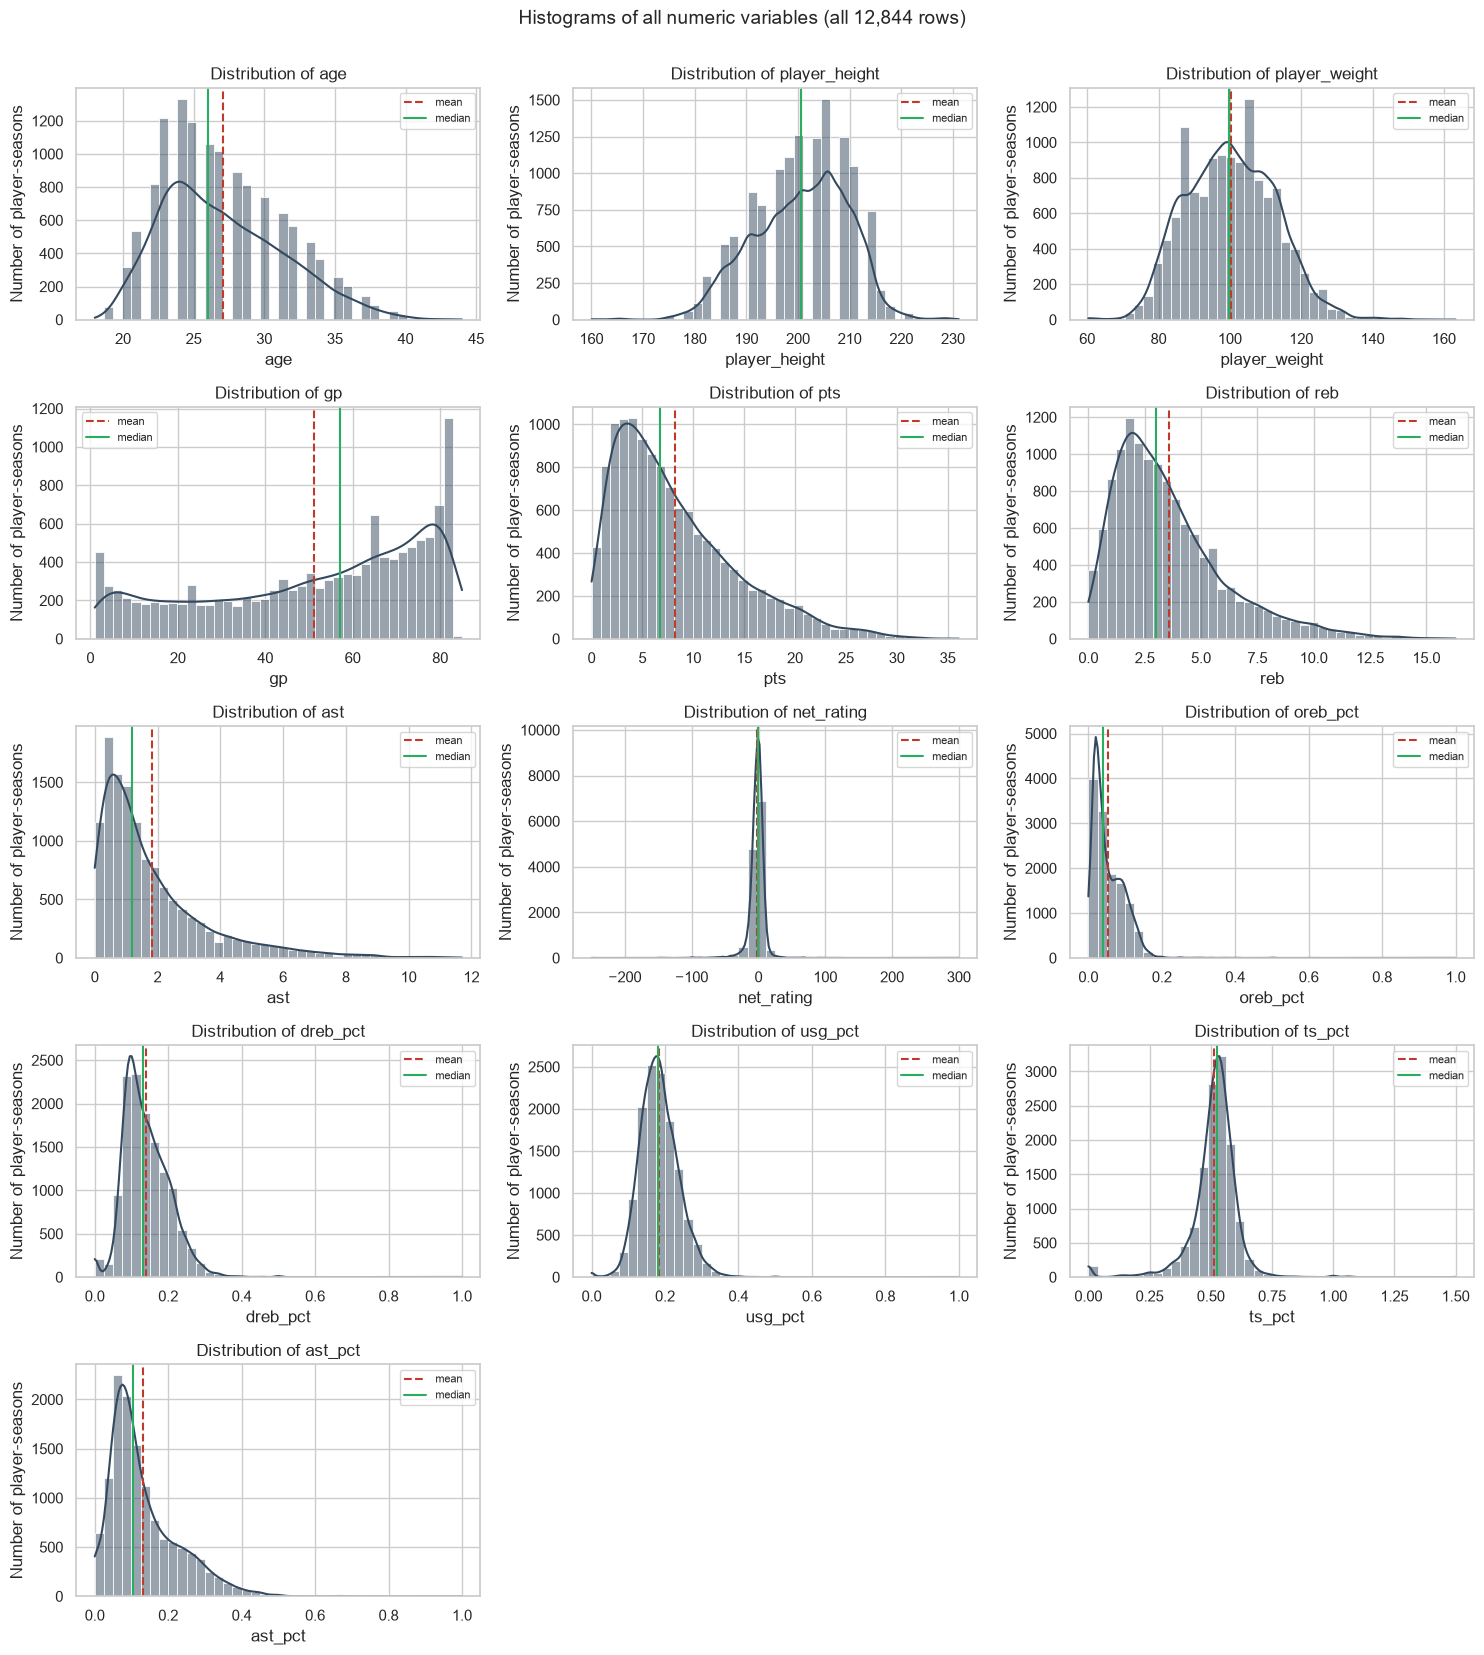

In [12]:
def plot_histogram_grid(df: pd.DataFrame, columns: list, n_columns: int = 3) -> None:
    """Histogram + KDE for each column, with mean (red) and median (green) lines."""
    n_rows = int(np.ceil(len(columns) / n_columns))
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 3.3 * n_rows))
    for axis, column in zip(axes.ravel(), columns):
        sns.histplot(df[column], bins=40, kde=True, ax=axis, color="#34495e")
        axis.axvline(df[column].mean(), color="#c0392b", linestyle="--", label="mean")
        axis.axvline(df[column].median(), color="#27ae60", linestyle="-", label="median")
        axis.set_title(f"Distribution of {column}")
        axis.set_xlabel(column)
        axis.set_ylabel("Number of player-seasons")
        axis.legend(fontsize=8)
    for axis in axes.ravel()[len(columns):]:
        axis.set_visible(False)
    fig.suptitle("Histograms of all numeric variables (all 12,844 rows)", y=1.002, fontsize=14)
    plt.tight_layout()
    plt.show()


plot_histogram_grid(clean_df, NUMERIC_COLUMNS)

In [13]:
# Normality check (D'Agostino-Pearson). With n ~ 12,800 even tiny deviations are "significant",
# so skewness/kurtosis above are more informative than the p-value.
normality_p_values = pd.Series({c: stats.normaltest(clean_df[c]).pvalue for c in NUMERIC_COLUMNS}, name="normaltest_p")
display(normality_p_values.to_frame().T)

,age,player_height,player_weight,gp,pts,reb,ast,net_rating,oreb_pct,dreb_pct,usg_pct,ts_pct,ast_pct
normaltest_p,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


**Skewness and shape**
* **Right-skewed:** `pts` (1.08), `reb` (1.29), `ast` (1.86), `oreb_pct` (2.34). Many bench players and a few stars: mean `pts` = 8.2 vs median 6.7.
* **Left-skewed:** `ts_pct` (−1.43) and `gp` (−0.53). `gp` shows a large block of near-full-season players (a spike at 80+ games), a second spike at 1–2 games and a flat stretch in between.
* **Close to symmetric:** `age` (0.57, mild right skew), `player_height` (−0.32) and `player_weight` (0.19). Note that the height histogram has **two bumps** (around 190 cm for guards and 206 cm for big men), so its mean and median fall in the valley between two groups and describe few actual players.
* **Heavy tails:** kurtosis of `net_rating` is 77.8, `oreb_pct` 25.0 and `ts_pct` 11.1 – all driven by tiny-sample rows. For `net_rating`, the standard deviation is 12.7 but the MAD is only 4.8 – the *classical* spread is inflated by a handful of rows.
* Normality tests reject normality for every variable, but with n ≈ 12,800 this is expected; skewness and kurtosis are more informative.

#### Outlier detection – three one-dimensional methods
1. **Z-score**: `|z| > 3`  2. **Tukey IQR fences**: outside `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]`  3. **Modified Z-score (MAD based)**: `|0.6745·(x - median)/MAD| > 3.5`

In [14]:
def zscore_outliers(values: pd.Series, threshold: float = 3.0) -> pd.Series:
    z_scores = (values - values.mean()) / values.std()
    return z_scores.abs() > threshold


def iqr_outliers(values: pd.Series, factor: float = 1.5) -> pd.Series:
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (values < q1 - factor * iqr) | (values > q3 + factor * iqr)


def modified_zscore_outliers(values: pd.Series, threshold: float = 3.5) -> pd.Series:
    mad = median_absolute_deviation(values)
    if mad == 0:  # more than half of the values are identical -> method undefined
        return pd.Series(False, index=values.index)
    modified_z = 0.6745 * (values - values.median()) / mad
    return modified_z.abs() > threshold


def build_outlier_table(df: pd.DataFrame, columns: list) -> pd.DataFrame:
    """Outlier counts (and % of rows) for each method and column."""
    rows = {}
    for column in columns:
        masks = {"zscore": zscore_outliers(df[column]), "iqr": iqr_outliers(df[column]), "modified_z_mad": modified_zscore_outliers(df[column])}
        rows[column] = {f"{name}_n": int(mask.sum()) for name, mask in masks.items()}
        rows[column].update({f"{name}_pct": mask.mean() * 100 for name, mask in masks.items()})
        rows[column]["flagged_by_all_3"] = int((masks["zscore"] & masks["iqr"] & masks["modified_z_mad"]).sum())
    return pd.DataFrame(rows).T


display(build_outlier_table(clean_df, NUMERIC_COLUMNS))

,zscore_n,iqr_n,modified_z_mad_n,zscore_pct,iqr_pct,modified_z_mad_pct,flagged_by_all_3
age,18.000,47.000,9.000,0.140,0.366,0.070,9.000
player_height,39.000,19.000,5.000,0.304,0.148,0.039,5.000
player_weight,54.000,57.000,15.000,0.420,0.444,0.117,15.000
gp,0.000,0.000,0.000,0.000,0.000,0.000,0.000
pts,145.000,298.000,187.000,1.129,2.320,1.456,145.000
reb,197.000,524.000,270.000,1.534,4.080,2.102,197.000
ast,268.000,841.000,763.000,2.087,6.548,5.941,268.000
net_rating,195.000,622.000,412.000,1.518,4.843,3.208,195.000
oreb_pct,61.000,78.000,90.000,0.475,0.607,0.701,61.000
dreb_pct,83.000,137.000,65.000,0.646,1.067,0.506,65.000


In [15]:
# Are the outliers real stars or small-sample artefacts? Median games played of IQR-outliers vs the rest.
sample_size_check = {}
for column in ["pts", "reb", "ast", "net_rating", "usg_pct", "ts_pct", "oreb_pct", "ast_pct"]:
    outlier_mask = iqr_outliers(clean_df[column])
    sample_size_check[column] = {
        "median_gp_outliers": clean_df.loc[outlier_mask, "gp"].median(),
        "median_gp_others": clean_df.loc[~outlier_mask, "gp"].median(),
        "share_of_outliers_with_gp<20_%": (clean_df.loc[outlier_mask, "gp"] < MIN_GAMES_FOR_RELIABLE_STATS).mean() * 100,
    }
display(pd.DataFrame(sample_size_check).T)

print("Top scoring seasons (genuine outliers):")
display(clean_df.nlargest(5, "pts")[["player_name", "season", "team_abbreviation", "gp", "pts", "usg_pct", "ts_pct"]])

,median_gp_outliers,median_gp_others,share_of_outliers_with_gp<20_%
pts,71.500,57.000,0.336
reb,72.000,56.000,1.908
ast,70.000,56.000,2.140
net_rating,4.000,59.000,90.354
usg_pct,13.000,57.000,50.952
ts_pct,6.000,60.000,82.542
oreb_pct,6.000,57.000,76.923
ast_pct,65.000,57.000,20.000


Top scoring seasons (genuine outliers):


,player_name,season,team_abbreviation,gp,pts,usg_pct,ts_pct
10227,James Harden,2018-19,HOU,78,36.100,0.396,0.616
4163,Kobe Bryant,2005-06,LAL,80,35.400,0.384,0.559
10634,James Harden,2019-20,HOU,68,34.300,0.356,0.626
12839,Joel Embiid,2022-23,PHI,66,33.100,0.370,0.655
4302,Allen Iverson,2005-06,PHI,72,33.000,0.354,0.543


**Comparing the three methods**
* The **IQR rule flags the most** points (e.g. `ts_pct`: 842), the **z-score the fewest** (285): the outliers inflate the standard deviation, so the z-score partly "masks" them. The **MAD-based modified z-score** is robust and sits in between. Most z-score outliers are also flagged by the other two methods.
* **Not all outliers are the same kind.**
  * `pts`, `reb`, `ast`: outliers are **genuine** high-minute stars/big men (median 70+ games; only 0.3–2 % have fewer than 20 games). Example: James Harden's 36.1 points in 2018-19.
  * `net_rating`, `ts_pct`, `oreb_pct`, `usg_pct`: **90 %, 83 %, 78 % and 51 %** of the outliers come from players with fewer than 20 games – small-sample artefacts.
* **Decision:** keep genuine outliers; for ratio metrics use the `gp >= 20` sample instead of deleting rows with a statistical rule.

### 5.2 Categorical variables

In [16]:
def summarize_categorical(series: pd.Series, top_k: int = 5, coverage: float = 0.80) -> dict:
    """Frequency facts for one categorical variable."""
    counts = series.value_counts()
    shares = counts / counts.sum()
    cumulative_share = shares.cumsum()
    return {
        "n_categories": len(counts),
        "most_common": counts.index[0],
        "most_common_share_%": shares.iloc[0] * 100,
        f"top_{top_k}_share_%": shares.head(top_k).sum() * 100,
        "values_needed_for_80%": int((cumulative_share < 0.80).sum() + 1),
        "values_needed_for_90%": int((cumulative_share < 0.90).sum() + 1),
    }


def values_covering_share(series: pd.Series, coverage: float) -> list:
    """Smallest set of most-frequent values whose cumulative share reaches `coverage`."""
    cumulative_share = (series.value_counts() / len(series)).cumsum()
    return cumulative_share[: int((cumulative_share < coverage).sum() + 1)].index.tolist()


categorical_variables = ["country", "team_abbreviation", "franchise", "college_label", "draft_bucket", "season", "origin_group"]
display(pd.DataFrame({column: summarize_categorical(clean_df[column].astype(object)) for column in categorical_variables}).T)

print("Countries needed to cover 90% of rows:", values_covering_share(clean_df["country"], 0.90))
print("Colleges needed to cover 50% of rows (incl. 'No US college'):", len(values_covering_share(clean_df["college_label"], 0.50)), "values; first 8:", values_covering_share(clean_df["college_label"], 0.50)[:8])

,n_categories,most_common,most_common_share_%,top_5_share_%,values_needed_for_80%,values_needed_for_90%
country,82,USA,83.471,88.049,1,9
team_abbreviation,36,CLE,3.504,17.315,24,28
franchise,30,BKN,3.558,17.432,24,27
college_label,357,No US college,14.435,26.347,72,118
draft_bucket,5,Pick 15-30,25.888,100.000,4,5
season,27,2021-22,4.710,21.442,22,25
origin_group,2,USA,83.471,100.000,1,2


Countries needed to cover 90% of rows: ['USA', 'Canada', 'France', 'Australia', 'Spain', 'Brazil', 'Slovenia', 'Turkey', 'Croatia']
Colleges needed to cover 50% of rows (incl. 'No US college'): 23 values; first 8: ['No US college', 'Kentucky', 'Duke', 'North Carolina', 'UCLA', 'Arizona', 'Kansas', 'Connecticut']


Countries total: 82 | rare (<20 rows): 52 covering 3.1% of rows
Team abbreviations: 36 -> franchises after merging: 30
Rare draft categories (raw draft_round):


draft_round,1,2,Undrafted,3,4,0,6,7,8
rows,7351,3032,2411,20,12,6,5,5,2


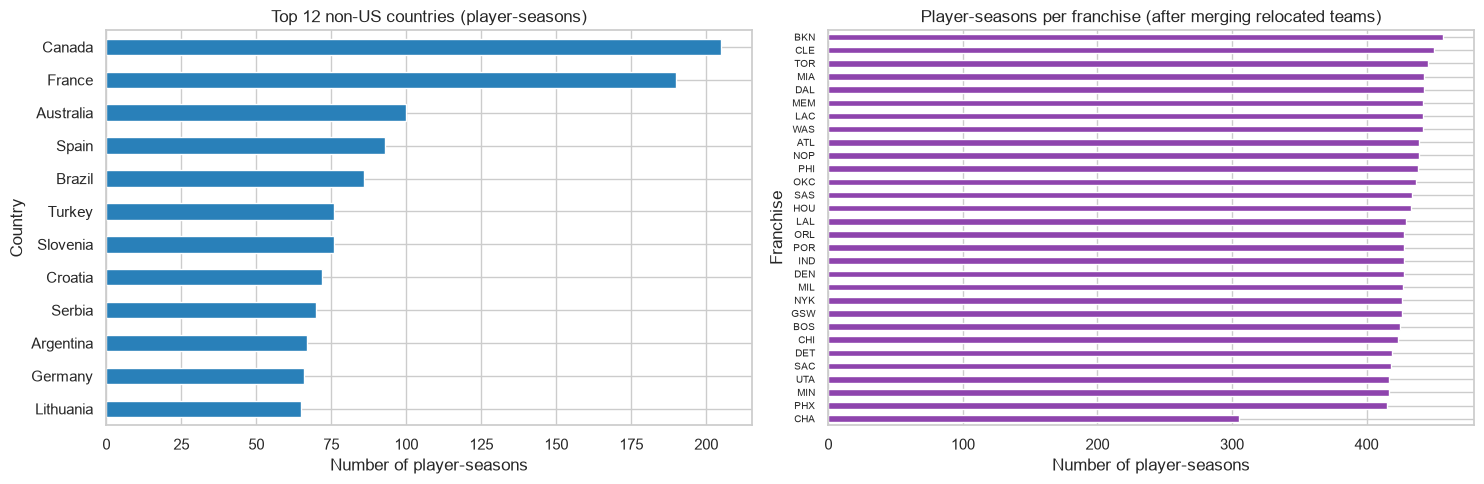

In [17]:
RARE_CATEGORY_THRESHOLD = 20
country_counts = clean_df["country"].value_counts()
rare_countries = country_counts[country_counts < RARE_CATEGORY_THRESHOLD]
print(f"Countries total: {len(country_counts)} | rare (<{RARE_CATEGORY_THRESHOLD} rows): {len(rare_countries)} "
      f"covering {rare_countries.sum() / len(clean_df):.1%} of rows")
print(f"Team abbreviations: {clean_df['team_abbreviation'].nunique()} -> franchises after merging: {clean_df['franchise'].nunique()}")
print("Rare draft categories (raw draft_round):")
display(raw_df["draft_round"].value_counts().to_frame("rows").T)

clean_df["country_group"] = clean_df["country"].where(~clean_df["country"].isin(rare_countries.index), "Other")
analysis_df["country_group"] = clean_df.loc[analysis_df.index, "country_group"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
country_counts.drop("USA").head(12).sort_values().plot.barh(ax=axes[0], color="#2980b9")
axes[0].set_title("Top 12 non-US countries (player-seasons)")
axes[0].set_xlabel("Number of player-seasons")
axes[0].set_ylabel("Country")
clean_df["franchise"].value_counts().sort_values().plot.barh(ax=axes[1], color="#8e44ad")
axes[1].set_title("Player-seasons per franchise (after merging relocated teams)")
axes[1].set_xlabel("Number of player-seasons")
axes[1].set_ylabel("Franchise")
axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

**Frequencies**
* **Country:** 82 categories, but **USA = 83.5 %** of rows; the top 5 cover 88 %; 9 countries (USA, Canada, France, Australia, Spain, Brazil, Slovenia, Turkey, Croatia) cover 90 %.
* **Team:** evenly spread (most common 3.5–3.6 %); 24 teams are needed for 80 %. After merging relocated teams there are 30 franchises.
* **College:** "No US college" is the most common label (14.4 %); 72 values are needed for 80 % and 23 for 50 % – a long tail led by Kentucky, Duke, North Carolina, UCLA.
* **Draft bucket:** Pick 15-30 is the largest (25.9 %); undrafted players are 18.8 %.

**Rare categories**
* 52 of 82 countries have fewer than 20 rows and together cover only **3.1 %** of the data – merging them into `"Other"` (`country_group`) loses little for modelling, although each is individually meaningful for a geographic story.
* `draft_round` values 3–8 are leftovers of old drafts with more than two rounds (merged into "Pick 31+"); round `0` is a placeholder (merged into "Undrafted").
* Team codes `NJN/SEA/VAN/NOH/NOK/CHH` are the same franchises under old names – merging them is *required*, not optional, to get correct per-team statistics.

**Discussion – do the central measures represent the data?**
* For `age` and `player_weight` the mean and median are close, so they describe the typical row well; `player_height` has almost identical mean and median but is bimodal (guards vs bigs), so a single centre is misleading.
* For `pts`, `reb`, `ast` the **mean overstates the typical player** (skew > 1); the median and MAD are the better summary.
* For `net_rating` and `ts_pct` the mean/std are distorted by tiny samples; after filtering `gp >= 20` the std of `net_rating` drops from 12.7 to 6.4.
* A single "average player" is also misleading structurally: the league is a mixture of guards and big men (height vs assists: −0.48), so one centre of the distribution describes nobody.

## 6. Correlations and relationships (20%)

### 6.1 Numeric vs numeric
Correlations below use `analysis_df` (rows with at least 20 games) because tiny samples distort ratio metrics (section 4.3 / 5.1). The effect of that choice is shown explicitly later.

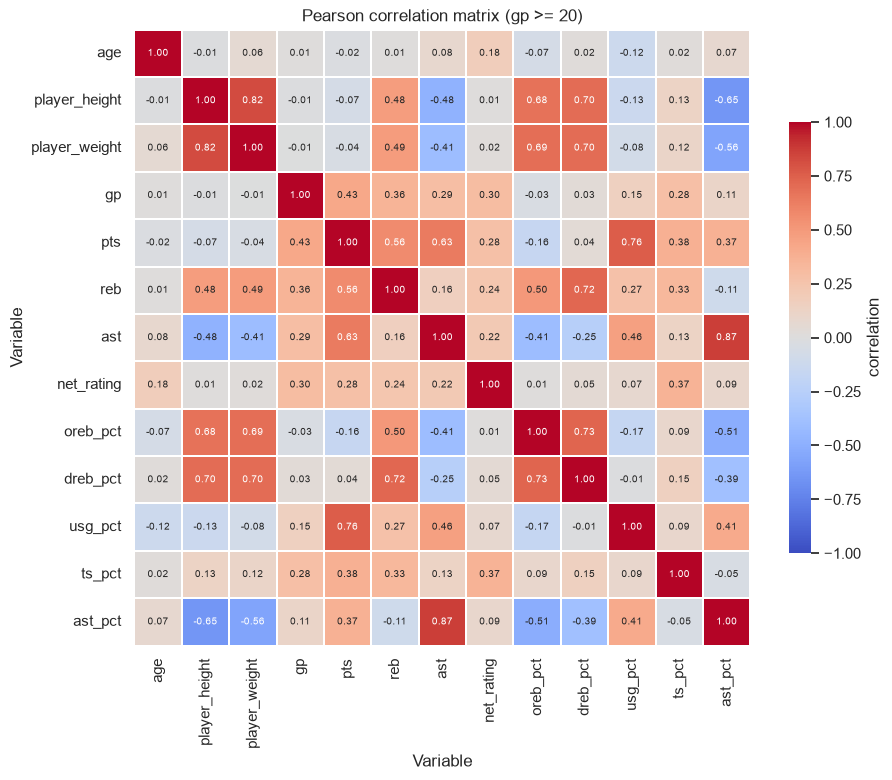

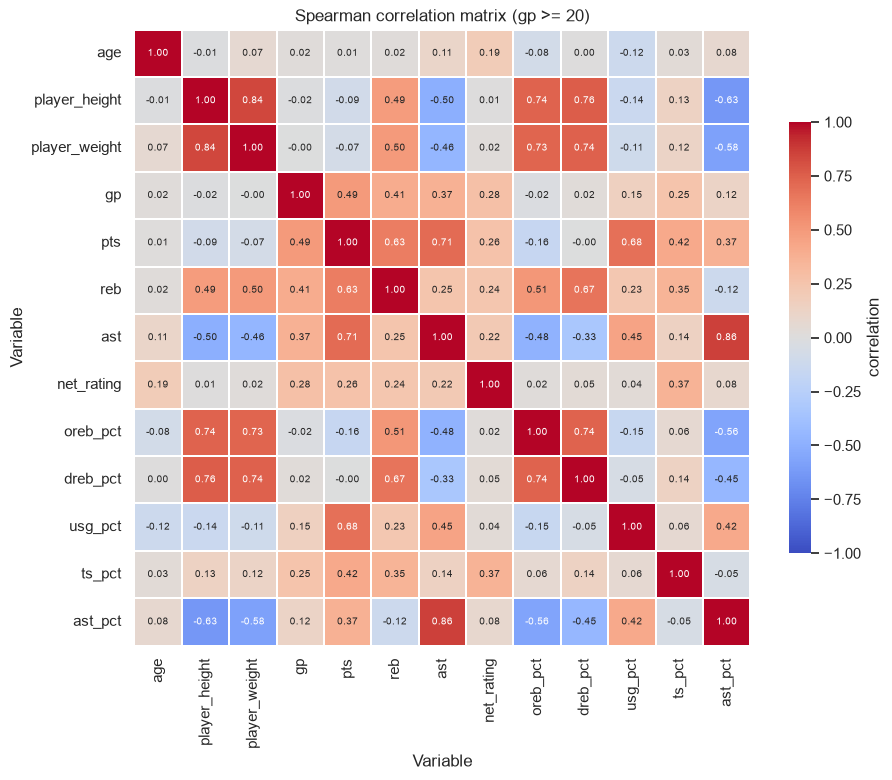

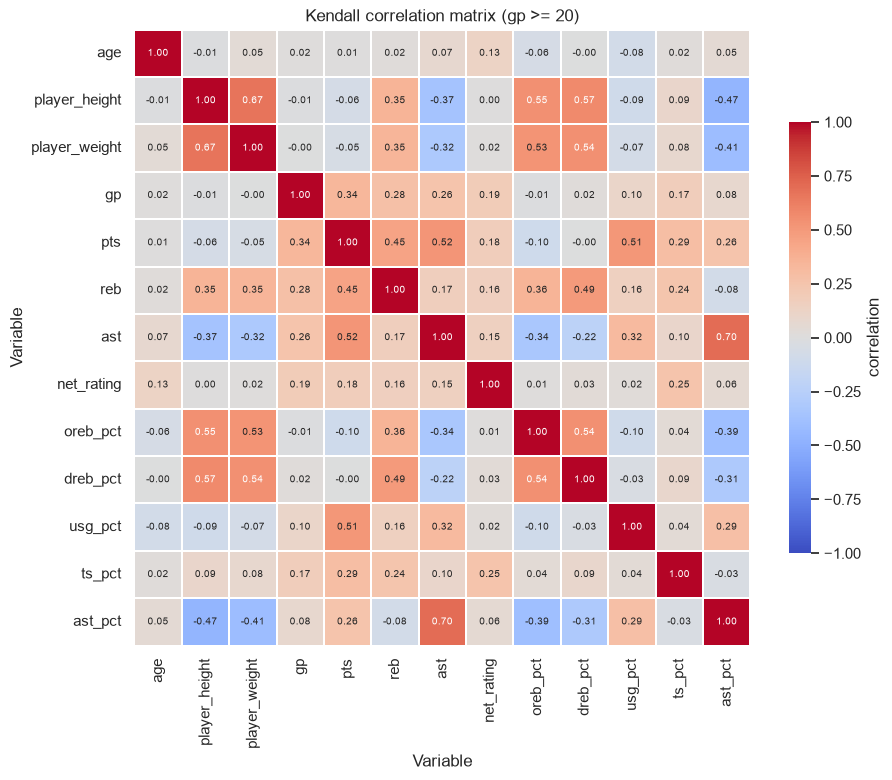

In [18]:
CORRELATION_METHODS = ["pearson", "spearman", "kendall"]
correlation_matrices = {method: analysis_df[NUMERIC_COLUMNS].corr(method=method) for method in CORRELATION_METHODS}


def plot_correlation_heatmap(correlation: pd.DataFrame, title: str) -> None:
    plt.figure(figsize=(10, 8))
    sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
                square=True, linewidths=0.3, annot_kws={"size": 7}, cbar_kws={"shrink": 0.7, "label": "correlation"})
    plt.title(title)
    plt.xlabel("Variable")
    plt.ylabel("Variable")
    plt.show()


for method in CORRELATION_METHODS:
    plot_correlation_heatmap(correlation_matrices[method], f"{method.capitalize()} correlation matrix (gp >= {MIN_GAMES_FOR_RELIABLE_STATS})")

In [19]:
def compute_pair_correlations(df: pd.DataFrame, pairs: list) -> pd.DataFrame:
    """Pearson, Spearman and Kendall coefficients for selected variable pairs."""
    rows = []
    for first, second in pairs:
        rows.append({
            "pair": f"{first} vs {second}",
            "pearson": stats.pearsonr(df[first], df[second])[0],
            "spearman": stats.spearmanr(df[first], df[second])[0],
            "kendall": stats.kendalltau(df[first], df[second])[0],
        })
    return pd.DataFrame(rows).set_index("pair")


KEY_PAIRS = [
    ("player_height", "player_weight"), ("player_height", "reb"), ("player_height", "ast"),
    ("usg_pct", "pts"), ("ast", "ast_pct"), ("reb", "dreb_pct"), ("ts_pct", "net_rating"),
    ("age", "net_rating"), ("age", "pts"), ("gp", "pts"),
]
key_pair_table = compute_pair_correlations(analysis_df, KEY_PAIRS)
key_pair_table["pearson_all_rows"] = compute_pair_correlations(clean_df, KEY_PAIRS)["pearson"]
key_pair_table["pearson_shift"] = key_pair_table["pearson"] - key_pair_table["pearson_all_rows"]
display(key_pair_table)

# Where do rank-based and linear coefficients disagree most? (non-linearity / outliers)
gap_matrix = (correlation_matrices["spearman"] - correlation_matrices["pearson"]).abs()
upper_triangle_gaps = gap_matrix.where(np.triu(np.ones(gap_matrix.shape, dtype=bool), k=1))
print("Largest |Spearman - Pearson| gaps:")
display(upper_triangle_gaps.stack().sort_values(ascending=False).head(6).to_frame("abs_gap"))

,pearson,spearman,kendall,pearson_all_rows,pearson_shift
pair,,,,,
player_height vs player_weight,0.825,0.836,0.671,0.822,0.003
player_height vs reb,0.477,0.490,0.355,0.424,0.052
player_height vs ast,-0.480,-0.503,-0.365,-0.443,-0.037
usg_pct vs pts,0.765,0.683,0.512,0.641,0.123
ast vs ast_pct,0.874,0.865,0.697,0.803,0.071
reb vs dreb_pct,0.720,0.671,0.495,0.612,0.108
ts_pct vs net_rating,0.366,0.367,0.254,0.313,0.053
age vs net_rating,0.178,0.189,0.131,0.093,0.085
age vs pts,-0.019,0.010,0.007,0.011,-0.030


Largest |Spearman - Pearson| gaps:


,,abs_gap
reb,ast,0.082
pts,usg_pct,0.082
ast,dreb_pct,0.077
gp,ast,0.074
pts,ast,0.074
ast,oreb_pct,0.071


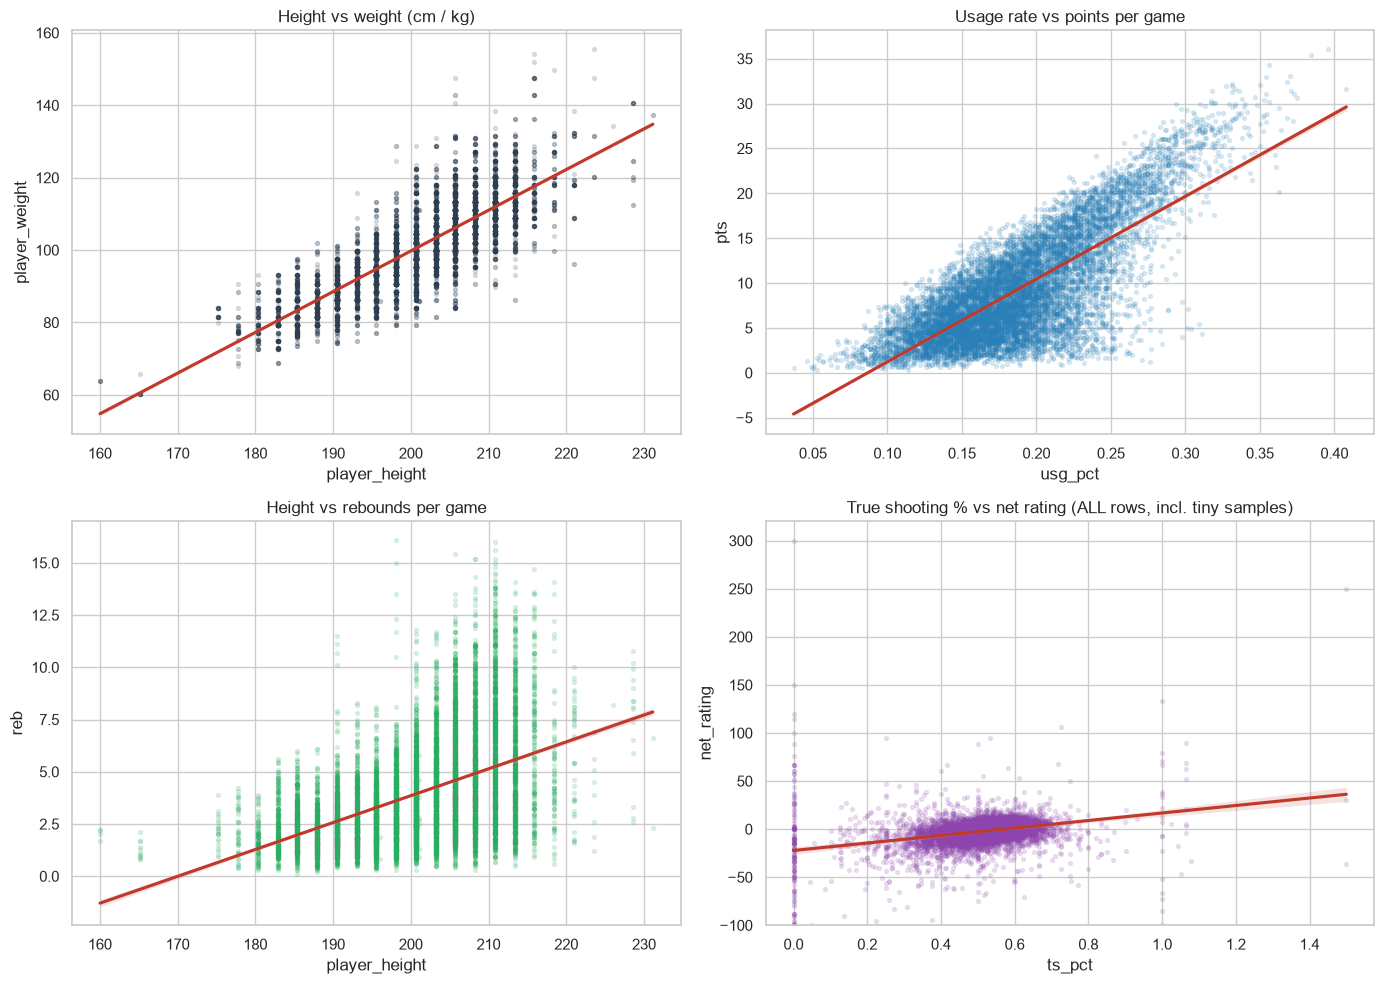

In [20]:
def scatter_with_trend(axis, data: pd.DataFrame, x: str, y: str, title: str, color: str) -> None:
    sns.regplot(data=data, x=x, y=y, ax=axis, scatter_kws={"alpha": 0.15, "s": 8, "color": color}, line_kws={"color": "#c0392b"})
    axis.set_title(title)
    axis.set_xlabel(x)
    axis.set_ylabel(y)


fig, axes = plt.subplots(2, 2, figsize=(14, 10))
scatter_with_trend(axes[0, 0], analysis_df, "player_height", "player_weight", "Height vs weight (cm / kg)", "#2c3e50")
scatter_with_trend(axes[0, 1], analysis_df, "usg_pct", "pts", "Usage rate vs points per game", "#2980b9")
scatter_with_trend(axes[1, 0], analysis_df, "player_height", "reb", "Height vs rebounds per game", "#27ae60")
scatter_with_trend(axes[1, 1], clean_df, "ts_pct", "net_rating", "True shooting % vs net rating (ALL rows, incl. tiny samples)", "#8e44ad")
axes[1, 1].set_ylim(-100, 320)
plt.tight_layout()
plt.show()

**Strongest relationships (rows with ≥ 20 games)**

| Pair | Pearson | Spearman | Kendall | Comment |
|---|---|---|---|---|
| height – weight | 0.83 | 0.84 | 0.67 | strong, monotonic and linear |
| ast – ast_pct | 0.87 | 0.87 | 0.70 | near-redundant (the share is computed from assists) |
| usg_pct – pts | 0.77 | 0.68 | 0.51 | strong, but convex / fan-shaped |
| reb – dreb_pct | 0.72 | 0.67 | 0.50 | near-redundant again |
| height – reb | 0.48 | 0.49 | 0.36 | taller → more rebounds |
| height – ast | −0.48 | −0.50 | −0.37 | taller → fewer assists (guards vs bigs; no `position` column, so height acts as a proxy) |
| ts_pct – net_rating | 0.37 | 0.37 | 0.25 | efficiency helps the team |
| age – pts | −0.02 | 0.01 | 0.01 | essentially no relation |

**Why three coefficients?** *Pearson* measures **linear** association and is sensitive to outliers; *Spearman* is Pearson on ranks (any **monotonic** relation, robust to outliers); *Kendall* counts concordant minus discordant pairs (probability-based, usually smaller in magnitude – roughly two thirds of Spearman – so its values must not be compared directly with the other two, only its ordering). When they agree (height–weight) the relation is monotonic and roughly linear; the largest Pearson/Spearman gaps in this data are only ≈ 0.08 (e.g. `pts`–`usg_pct`), which signals mild non-linearity (variance grows with usage).

**Effect of tiny samples:** filtering to `gp >= 20` raises Pearson correlations of ratio metrics by up to 0.12 (`usg_pct`–`pts`: 0.64 → 0.77; `reb`–`dreb_pct`: 0.61 → 0.72). The `gp`–`pts` correlation moves in the other direction (0.54 → 0.43) because the filter itself truncates `gp` – a reminder that filtering choices are analysis choices.

**Scatter-plot insights**
* Height/weight: clear positive cloud with vertical stripes (heights are whole inches).
* Usage vs points: a fan – scoring variance rises with usage.
* Height vs rebounds: at every height there is a wide spread, so height is *helpful but far from sufficient*.
* True shooting vs net rating (all rows): points at `ts_pct = 0`, `1.0`, `1.5` and `net_rating` up to 300 are tiny-sample artefacts that tilt the regression line.

**Caution:** these are correlations, not causes. Position, minutes and team quality are unobserved confounders.

### 6.2 Categorical vs categorical, binning, and categorical vs numeric

Row-normalised frequency table (%): draft_bucket x origin_group


origin_group,International,USA
draft_bucket,,
Top 5 pick,15.700,84.300
Pick 6-14,12.800,87.200
Pick 15-30,21.500,78.500
Pick 31+,17.900,82.100
Undrafted,16.500,83.500


Row-normalised frequency table (%): era x origin_group


origin_group,International,USA
era,,
1996-2004,9.500,90.500
2005-2013,17.800,82.200
2014-2022,23.400,76.600


Row-normalised frequency table (%): height_class x scoring_tier


scoring_tier,Bench,Rotation,Starter,Star
height_class,,,,
Short,37.600,37.000,19.400,5.900
Medium,42.600,34.300,16.800,6.200
Tall,48.100,30.300,16.400,5.300


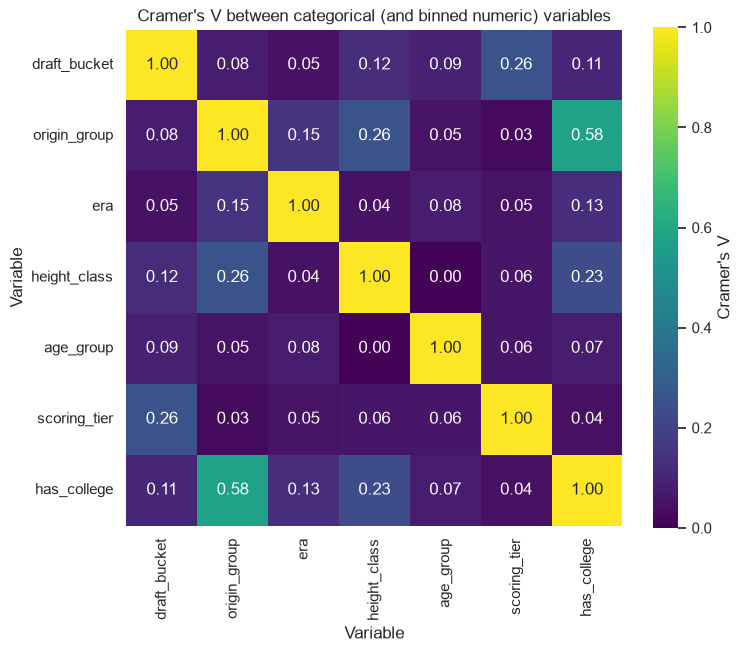

In [21]:
def cramers_v(first: pd.Series, second: pd.Series) -> float:
    """Bias-corrected Cramer's V (Bergsma 2013) in [0, 1]."""
    contingency = pd.crosstab(first, second)
    chi2_statistic = stats.chi2_contingency(contingency, correction=False)[0]
    n_observations = contingency.to_numpy().sum()
    n_rows, n_columns = contingency.shape
    phi_squared = chi2_statistic / n_observations
    phi_squared_corrected = max(0.0, phi_squared - (n_columns - 1) * (n_rows - 1) / (n_observations - 1))
    rows_corrected = n_rows - (n_rows - 1) ** 2 / (n_observations - 1)
    columns_corrected = n_columns - (n_columns - 1) ** 2 / (n_observations - 1)
    return float(np.sqrt(phi_squared_corrected / min(columns_corrected - 1, rows_corrected - 1)))


CATEGORICAL_COLUMNS = ["draft_bucket", "origin_group", "era", "height_class", "age_group", "scoring_tier", "has_college"]
for row_variable, column_variable in [("draft_bucket", "origin_group"), ("era", "origin_group"), ("height_class", "scoring_tier")]:
    print(f"Row-normalised frequency table (%): {row_variable} x {column_variable}")
    display((pd.crosstab(analysis_df[row_variable], analysis_df[column_variable], normalize="index") * 100).round(1))

cramers_v_matrix = pd.DataFrame(
    [[cramers_v(analysis_df[a], analysis_df[b]) if a != b else 1.0 for b in CATEGORICAL_COLUMNS] for a in CATEGORICAL_COLUMNS],
    index=CATEGORICAL_COLUMNS, columns=CATEGORICAL_COLUMNS,
)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cramers_v_matrix, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, square=True, cbar_kws={"label": "Cramer's V"})
plt.title("Cramer's V between categorical (and binned numeric) variables")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.show()

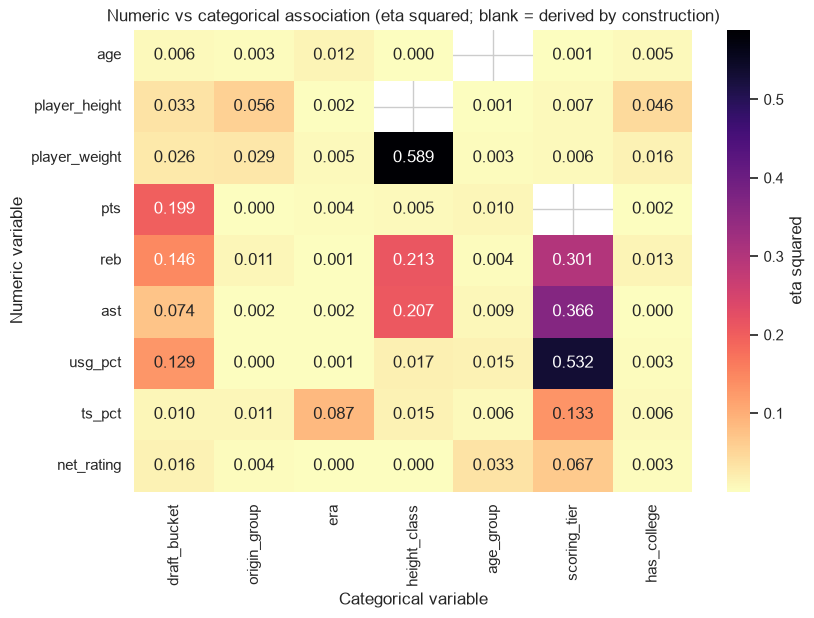

Kruskal-Wallis p-values for selected pairs:


,p_value
pts by draft_bucket,0.000
net_rating by draft_bucket,0.000
reb by height_class,0.000
ast by height_class,0.000
ts_pct by era,0.000
age by draft_bucket,0.000


In [22]:
def eta_squared(values: pd.Series, groups: pd.Series) -> float:
    """Share of the variance of `values` explained by group membership (0..1)."""
    frame = pd.DataFrame({"value": values, "group": groups}).dropna()
    grand_mean = frame["value"].mean()
    total_sum_squares = ((frame["value"] - grand_mean) ** 2).sum()
    group_stats = frame.groupby("group", observed=True)["value"].agg(["count", "mean"])
    between_sum_squares = (group_stats["count"] * (group_stats["mean"] - grand_mean) ** 2).sum()
    return float(between_sum_squares / total_sum_squares)


def kruskal_p_value(values: pd.Series, groups: pd.Series) -> float:
    frame = pd.DataFrame({"value": values, "group": groups}).dropna()
    samples = [group["value"].to_numpy() for _, group in frame.groupby("group", observed=True)]
    return float(stats.kruskal(*samples).pvalue)


ASSOCIATION_NUMERIC = ["age", "player_height", "player_weight", "pts", "reb", "ast", "usg_pct", "ts_pct", "net_rating"]
DERIVED_BY_CONSTRUCTION = {("pts", "scoring_tier"), ("player_height", "height_class"), ("age", "age_group")}

eta_squared_matrix = pd.DataFrame(
    {
        categorical: {
            numeric: np.nan if (numeric, categorical) in DERIVED_BY_CONSTRUCTION else eta_squared(analysis_df[numeric], analysis_df[categorical])
            for numeric in ASSOCIATION_NUMERIC
        }
        for categorical in CATEGORICAL_COLUMNS
    }
)
plt.figure(figsize=(9, 6))
sns.heatmap(eta_squared_matrix, annot=True, fmt=".3f", cmap="magma_r", cbar_kws={"label": "eta squared"})
plt.title("Numeric vs categorical association (eta squared; blank = derived by construction)")
plt.xlabel("Categorical variable")
plt.ylabel("Numeric variable")
plt.show()

print("Kruskal-Wallis p-values for selected pairs:")
selected_tests = [("pts", "draft_bucket"), ("net_rating", "draft_bucket"), ("reb", "height_class"), ("ast", "height_class"), ("ts_pct", "era"), ("age", "draft_bucket")]
display(pd.Series({f"{n} by {c}": kruskal_p_value(analysis_df[n], analysis_df[c]) for n, c in selected_tests}, name="p_value").to_frame())

**Frequency tables and Cramér's V (bias-corrected)**
* The **international share rises by era: 9.5 % → 17.8 % → 23.4 %** (V = 0.15).
* Draft bucket vs origin: V = 0.08 – international players are spread over all draft buckets (13–22 %).
* Height class vs scoring tier: V = 0.06. Tall players are *more* often "Bench" (48 % vs 38 % for short players) but are equally likely to be "Stars" (5–6 %) – size does not decide who scores the most.
* Strongest associations: `has_college` – `origin_group` (V = 0.58, almost the same information), `scoring_tier` – `draft_bucket` (0.26), `origin_group` – `height_class` (0.26; international players are taller: mean 205 vs 200 cm).

**Binning.** Continuous variables were binned to be compared with categoricals: `height_class` (terciles via `qcut`), `scoring_tier` (50 / 80 / 95 % quantiles of `pts`), `age_group` and `era` (fixed edges via `cut`). Cost of binning: lost information and results that depend on cut points; pairs that are derived by construction (e.g. `pts` vs `scoring_tier`) are left blank in the heatmap.

**Numeric vs categorical (eta squared = share of variance explained)**
* `draft_bucket` explains **20 % of the variance of `pts`**, 15 % of `reb` and 13 % of `usg_pct` – draft position is the best categorical predictor of production.
* `height_class` explains 21 % of `reb`, 21 % of `ast` (opposite signs) and 59 % of `player_weight`.
* `era` explains 8.7 % of `ts_pct` (efficiency changed over time).
* `net_rating` is hardly explained by any category (≤ 7 %), and `origin_group` explains almost no production variable (but 5.6 % of height).
* Kruskal-Wallis p-values are all ≈ 0, which is unsurprising for n ≈ 10,700; **the effect sizes are the informative part**.

### 6.3 Graphs (each with title, axis labels and an insight)

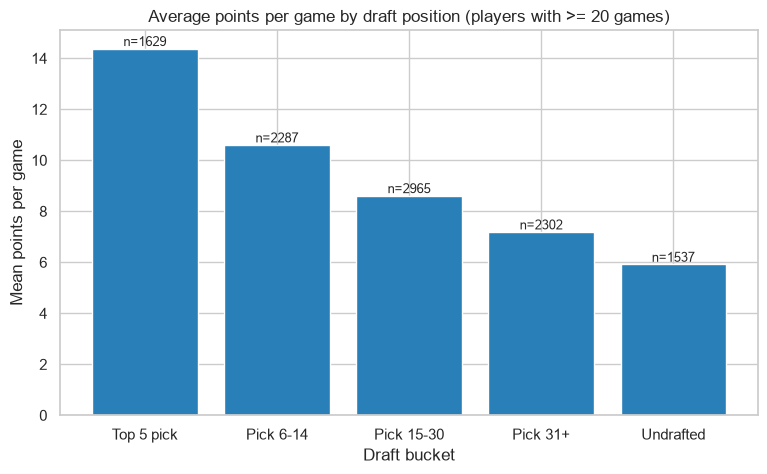

In [23]:
# Bar chart - average points per game by draft bucket (with sample sizes)
mean_points_by_bucket = analysis_df.groupby("draft_bucket", observed=True)["pts"].agg(["mean", "count"])
fig, axis = plt.subplots(figsize=(9, 5))
bars = axis.bar(mean_points_by_bucket.index.astype(str), mean_points_by_bucket["mean"], color="#2980b9")
for bar, count in zip(bars, mean_points_by_bucket["count"]):
    axis.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1, f"n={count}", ha="center", fontsize=9)
axis.set_title("Average points per game by draft position (players with >= 20 games)")
axis.set_xlabel("Draft bucket")
axis.set_ylabel("Mean points per game")
plt.show()

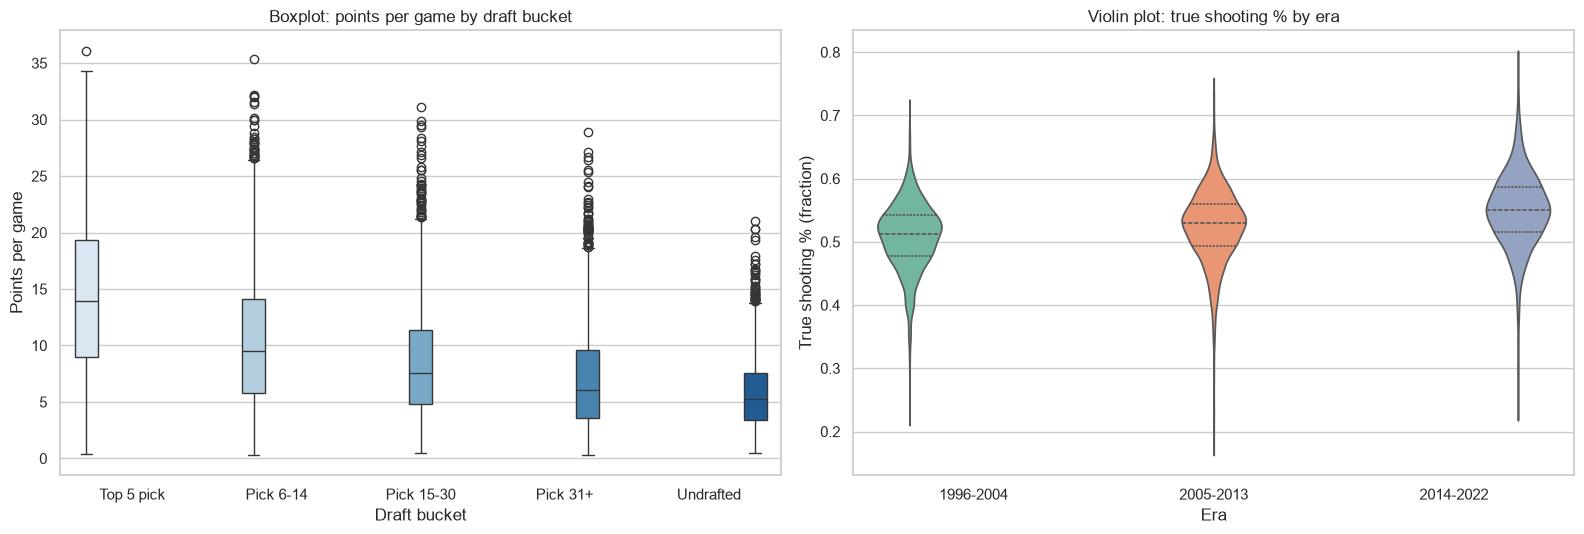

In [24]:
# Boxplot + violin plot side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.boxplot(data=analysis_df, x="draft_bucket", y="pts", hue="draft_bucket", palette="Blues", legend=False, ax=axes[0])
axes[0].set_title("Boxplot: points per game by draft bucket")
axes[0].set_xlabel("Draft bucket")
axes[0].set_ylabel("Points per game")
sns.violinplot(data=analysis_df, x="era", y="ts_pct", hue="era", palette="Set2", inner="quartile", legend=False, ax=axes[1])
axes[1].set_title("Violin plot: true shooting % by era")
axes[1].set_xlabel("Era")
axes[1].set_ylabel("True shooting % (fraction)")
plt.tight_layout()
plt.show()

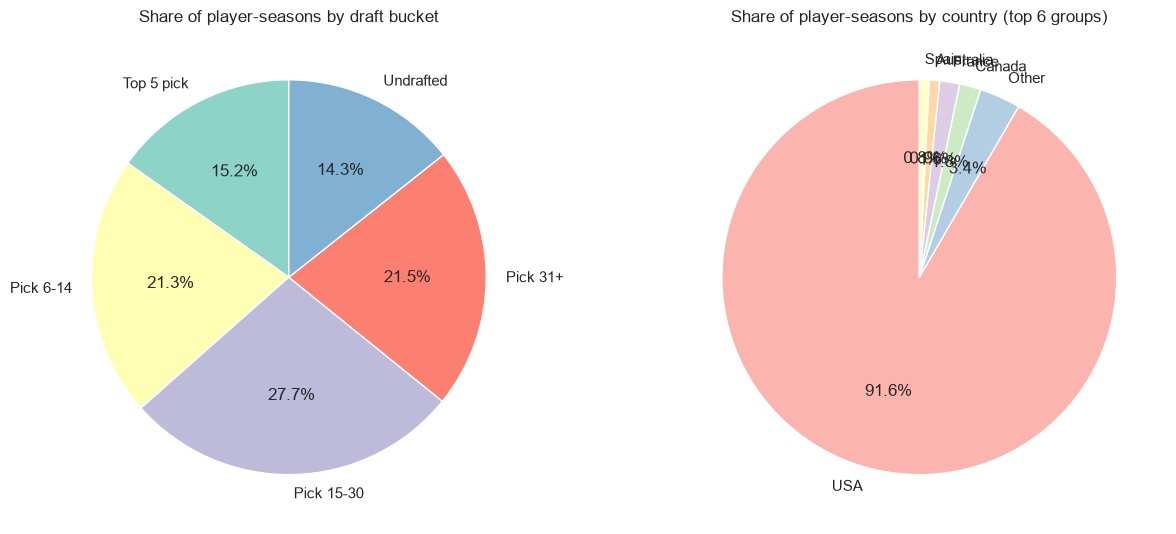

In [25]:
# Pie charts - composition of the data
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
analysis_df["draft_bucket"].value_counts().reindex(DRAFT_BUCKET_ORDER).plot.pie(ax=axes[0], autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set3"))
axes[0].set_title("Share of player-seasons by draft bucket")
axes[0].set_ylabel("")
clean_df["country_group"].value_counts().head(6).plot.pie(ax=axes[1], autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Pastel1"))
axes[1].set_title("Share of player-seasons by country (top 6 groups)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

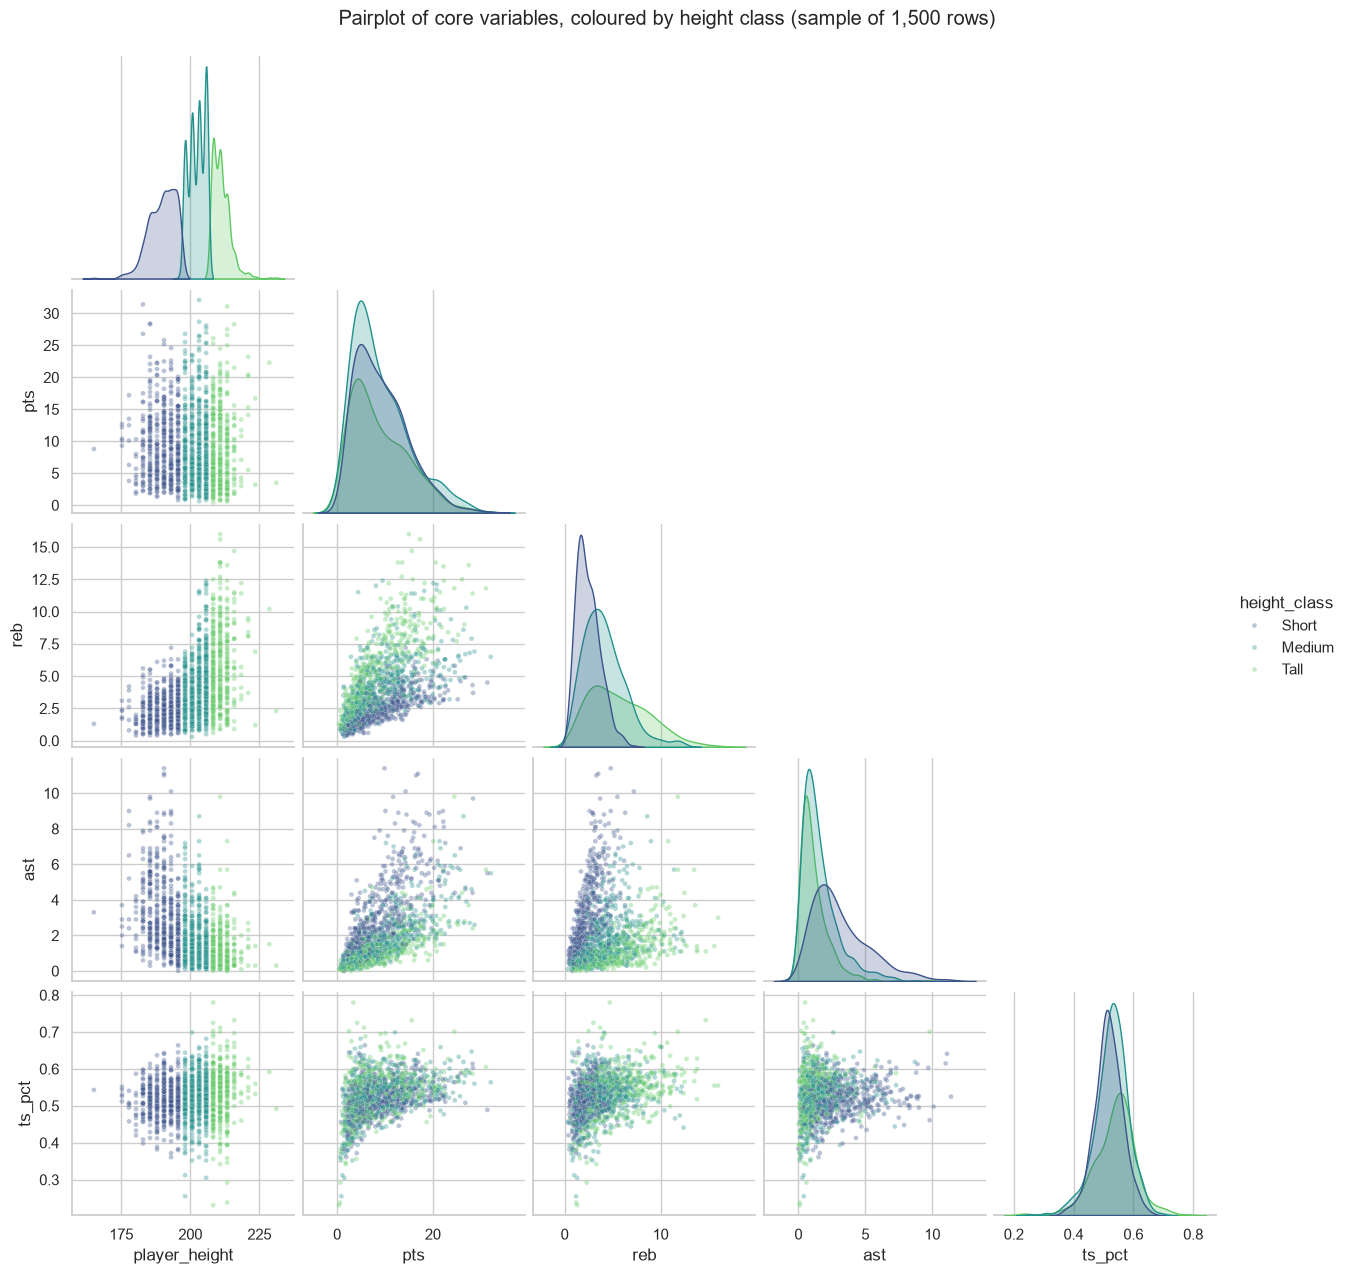

In [26]:
# Pairplot (random sample for speed)
pairplot_sample = analysis_df.sample(1500, random_state=RANDOM_STATE)
pair_grid = sns.pairplot(
    pairplot_sample, vars=["player_height", "pts", "reb", "ast", "ts_pct"], hue="height_class",
    palette="viridis", plot_kws={"alpha": 0.35, "s": 12}, corner=True,
)
pair_grid.figure.suptitle("Pairplot of core variables, coloured by height class (sample of 1,500 rows)", y=1.02)
plt.show()

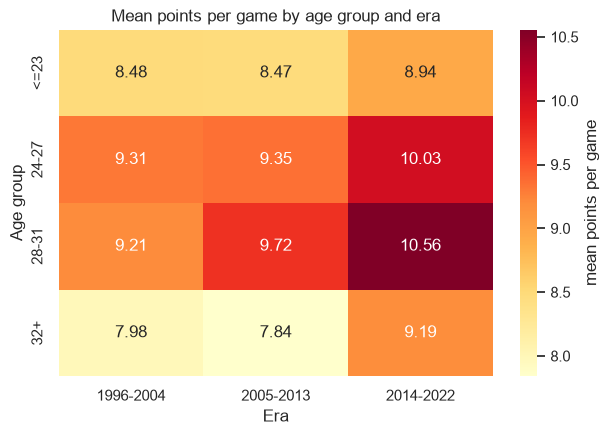

In [27]:
# Heatmap: mean points by age group and era
mean_points_pivot = analysis_df.pivot_table(index="age_group", columns="era", values="pts", aggfunc="mean", observed=True)
plt.figure(figsize=(7, 4.5))
sns.heatmap(mean_points_pivot, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={"label": "mean points per game"})
plt.title("Mean points per game by age group and era")
plt.xlabel("Era")
plt.ylabel("Age group")
plt.show()

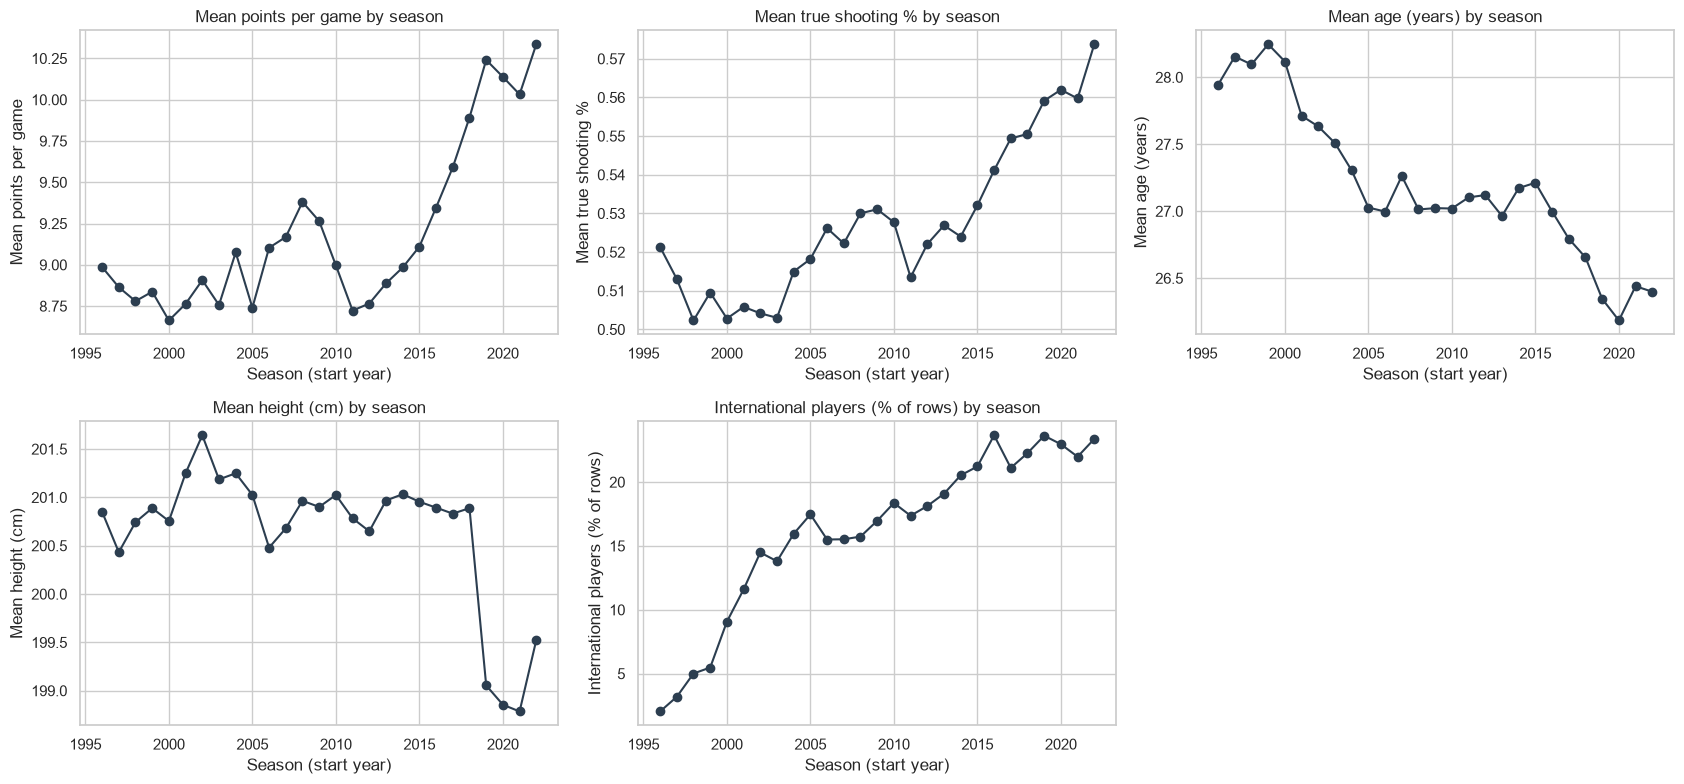

In [28]:
# Extra: league-level trends over time
yearly_trends = analysis_df.groupby("season_start").agg(
    mean_points=("pts", "mean"), mean_ts_pct=("ts_pct", "mean"), mean_age=("age", "mean"), mean_height_cm=("player_height", "mean"),
)
yearly_trends["international_share_pct"] = clean_df.groupby("season_start")["is_international"].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
trend_titles = {
    "mean_points": "Mean points per game", "mean_ts_pct": "Mean true shooting %", "mean_age": "Mean age (years)",
    "mean_height_cm": "Mean height (cm)", "international_share_pct": "International players (% of rows)",
}
for axis, (column, title) in zip(axes.ravel(), trend_titles.items()):
    axis.plot(yearly_trends.index, yearly_trends[column], marker="o", color="#2c3e50")
    axis.set_title(f"{title} by season")
    axis.set_xlabel("Season (start year)")
    axis.set_ylabel(title)
axes[1, 2].axis("off")
plt.tight_layout()
plt.show()

**What the graphs tell us**
* **Bar chart:** average points fall steadily with draft position – 14.4 (top-5 pick) → 10.6 → 8.6 → 7.2 → 5.9 (undrafted).
* **Box plot:** the distributions overlap heavily and every bucket has high outliers – draft position shifts the average, but undrafted stars exist.
* **Violin plot:** the true-shooting distribution moves up and narrows from era to era (the league became more efficient).
* **Pie charts:** draft buckets are fairly balanced; the US dominates the country composition (pie charts make small slices hard to compare – a bar chart is better for precise reading).
* **Pair plot:** height separates rebounds and assists (tall: more rebounds, fewer assists); `ts_pct` is roughly unimodal.
* **Heatmap:** mean points rise from the first to the last era in every age group (e.g. 28-31: 9.2 → 10.6) and the 24-31 age groups score the most.
* **Trend lines (extra):** scoring and true shooting accelerate after about 2013; the mean age falls from ~28.2 (1999) to ~26.2 (2020); the international share grows from ~2 % (1996) to ~23 % (2022); mean height drops by ~1.5 cm in 2019-20 – a **measurement artefact** examined in 9.1b.

## 7. Index analysis (5%)

In [29]:
def build_index_report(df: pd.DataFrame) -> pd.Series:
    """Answer: is the index unique, time-based, sorted, and what does it encode?"""
    season_start = df["season"].str[:4].astype(int)
    return pd.Series({
        "index_type": type(df.index).__name__,
        "index_is_unique": df.index.is_unique,
        "index_is_datetime": isinstance(df.index, pd.DatetimeIndex),
        "index_is_monotonic_increasing": df.index.is_monotonic_increasing,
        "export_column_equals_index": bool((df["Unnamed: 0"] == df.index).all()),
        "rows_sorted_by_season": season_start.is_monotonic_increasing,
        "(player_name, season, age) is a unique key": not df.duplicated(["player_name", "season", "age"]).any(),
    })


display(build_index_report(raw_df).to_frame("value"))

# Is the order of rows inside a season sorted by any column?
season_groups = raw_df.assign(season_start=season_start_raw).groupby("season_start")
sorted_within_season = {
    column: bool(season_groups[column].apply(lambda s: s.is_monotonic_increasing or s.is_monotonic_decreasing).all())
    for column in NUMERIC_COLUMNS + ["player_name"]
}
print("Columns sorted inside every season:", [c for c, flag in sorted_within_season.items() if flag] or "none")

,value
index_type,RangeIndex
index_is_unique,True
index_is_datetime,False
index_is_monotonic_increasing,True
export_column_equals_index,True
rows_sorted_by_season,True
"(player_name, season, age) is a unique key",True


Columns sorted inside every season: none


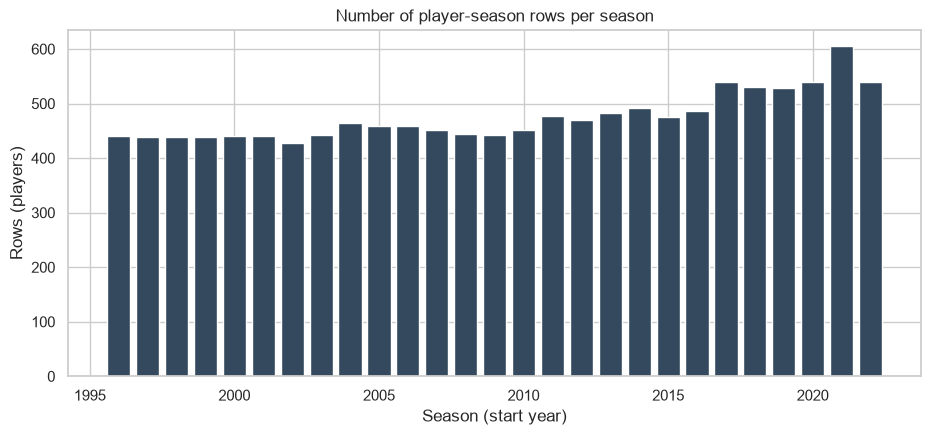

Spearman correlation per era:


,1996-2004,2005-2013,2014-2022
player_height vs player_weight,0.843,0.842,0.811
usg_pct vs pts,0.663,0.687,0.714
player_height vs reb,0.479,0.491,0.498
age vs net_rating,0.173,0.192,0.203


In [30]:
# Does the analysis change over time? Rows per season and key relationships per era.
rows_per_season = clean_df.groupby("season_start").size()
fig, axis = plt.subplots(figsize=(11, 4.5))
axis.bar(rows_per_season.index, rows_per_season.values, color="#34495e")
axis.set_title("Number of player-season rows per season")
axis.set_xlabel("Season (start year)")
axis.set_ylabel("Rows (players)")
plt.show()

era_pairs = [("player_height", "player_weight"), ("usg_pct", "pts"), ("player_height", "reb"), ("age", "net_rating")]
correlation_by_era = pd.DataFrame({
    era: {f"{a} vs {b}": stats.spearmanr(group[a], group[b])[0] for a, b in era_pairs}
    for era, group in analysis_df.groupby("era", observed=True)
})
print("Spearman correlation per era:")
display(correlation_by_era)

**Index analysis**
* The index is a `RangeIndex` 0…12,843: **unique and monotonic, but not time-based** (not a `DatetimeIndex`). `Unnamed: 0` is a copy of it – an artefact of saving a DataFrame with its index.
* **Sorted?** Rows are sorted by season (non-decreasing), so *row position encodes time*; inside a season no column is sorted, i.e. the order is arbitrary. Consequence: a naive "last 20 % of rows" split is a temporal split, while a random split mixes eras.
* **Natural key:** `(player_name, season, age)` is unique; `player_name` alone is not.
* **Does the analysis change over time?** Yes, in *levels*: rows per season grow from 441 to 605 (league expansion and roster-rule changes), and the mean of `ts_pct`, `age` and the international share all drift. The *relationships* are stable across eras (Spearman height–weight 0.84 → 0.81, height–rebounds 0.48 → 0.50, usage–points 0.66 → 0.71). Pooled summary statistics are therefore mixtures of different eras.

## 8. Insights and data story (15%)

### 8.1 Key insights
1. **Draft position is the strongest categorical signal of production.** Top-5 picks average 14.4 points per game versus 5.9 for undrafted players; `draft_bucket` explains about 20 % of the variance of points (eta² = 0.20) and 15 % of rebounds – but the distributions overlap heavily.
2. **Body size separates roles.** Height correlates +0.48 with rebounds and −0.48 with assists (guards vs big men). With no `position` column in the file, height and weight act as a proxy for position.
3. **The league changed, the relationships did not.** League-average true shooting rose ≈ 0.22 percentage points per season (r = 0.88 on season means), mean points rose from ~8.7 to ~10.3, players became younger (28.2 → 26.2 years) and the international share grew from ~2 % to ~23 %. Correlations between variables stayed nearly constant across eras.
4. **Most "extreme" values are small-sample artefacts, not errors.** 90 % of `net_rating` outliers come from players with fewer than 20 games; the `gp >= 20` filter changes Pearson correlations by up to 0.12 and halves the standard deviation of `net_rating`.
5. **A measurement convention changed.** The listed height of the same players dropped by a median of one inch between 2018-19 and 2019-20 (section 9.1b).

### 8.2 Biases and risks
* **Survivorship / selection:** only players who reached an NBA court are present; "undrafted" or foreign players enter the data only if they made it.
* **Unequal weights:** a 1-game and an 82-game season are one row each.
* **Aggregation:** traded players are merged into one row (`gp` up to 85, one team code).
* **Missing context:** no minutes, position, injuries, salary or shot data; conclusions about causes are not possible.
* **False precision:** heights and weights are converted from inches/pounds; `age` is stored as float.
* **US-centric schema:** `college` assumes a US path, which makes missingness structurally linked to nationality.

### 8.3 Possible points of failure
**Engineering**
* Using `player_name` as a key (namesakes collide) or leaving `"Undrafted"` strings in numeric columns (type errors, wrong sorting).
* One-hot encoding 357 colleges or 82 countries (dimensionality, sparsity).
* Relocated franchises under different codes (wrong per-team aggregates).
* Training and testing on random splits: the same player appears in both sets (panel leakage) and eras are mixed (drift) – use player-grouped and time-based splits.

**Statistical**
* Averaging ratio metrics (`ts_pct`, `usg_pct`, `net_rating`) across rows without weighting by games or minutes.
* Using z-scores on skewed data, or trusting p-values at n ≈ 10,000 – effect sizes matter, and observations are not independent (same player, many seasons).
* Multicollinearity (`ast` ≈ `ast_pct`, `reb` ≈ `dreb_pct`) and circular variables (`scoring_tier` derived from `pts`).
* Treating the 2019-20 height drop as real change, or comparing eras without noting that the mix of players changed.

### 8.4 What I learned
I started with the assumption that a clean-looking sports table is "ground truth". The analysis showed that it is a **product of a measurement process**: the "missing" values mean something (nationality), the extreme values come from sample size, the identifier is not an identifier, and even something as objective as height changed with a convention. I also expected body size to predict scoring; it predicts *role* (rebounds vs assists) but hardly scoring, whereas draft position predicts scoring far better. The main lesson: before modelling, ask *what was measured, what is missing, what is biased, and what is artificially centred*.

## 9. Bonus

### 9.1 Time dependence and external knowledge

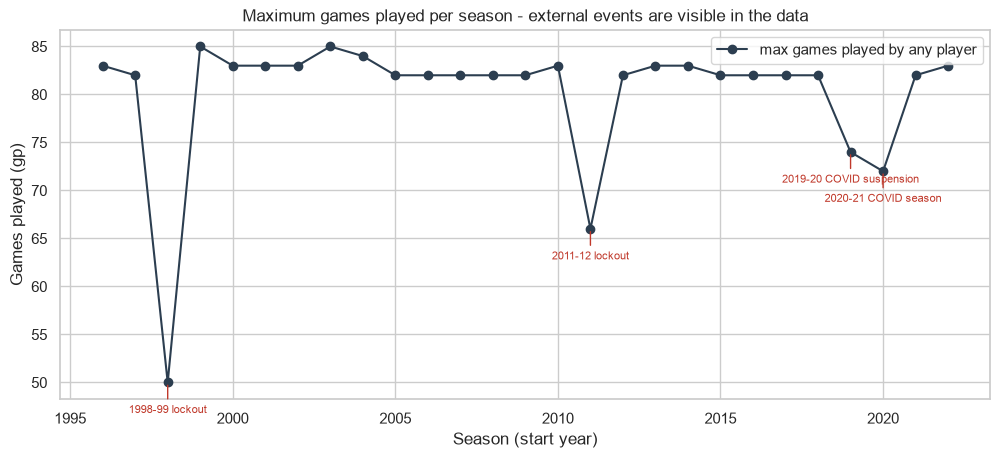

League-average true shooting % rose by 0.22 percentage points per season (r=0.88, p=1.6e-09).


In [31]:
# Games played per season vs known league events (lockouts, COVID).
max_games_per_season = clean_df.groupby("season_start")["gp"].max()
KNOWN_EVENTS = {1998: "1998-99 lockout", 2011: "2011-12 lockout", 2019: "2019-20 COVID suspension", 2020: "2020-21 COVID season"}

fig, axis = plt.subplots(figsize=(12, 4.8))
axis.plot(max_games_per_season.index, max_games_per_season.values, marker="o", color="#2c3e50", label="max games played by any player")
for season_year, label in KNOWN_EVENTS.items():
    axis.annotate(label, (season_year, max_games_per_season[season_year]), textcoords="offset points", xytext=(0, -22), ha="center", fontsize=8, color="#c0392b",
                  arrowprops={"arrowstyle": "-", "color": "#c0392b"})
axis.set_title("Maximum games played per season - external events are visible in the data")
axis.set_xlabel("Season (start year)")
axis.set_ylabel("Games played (gp)")
axis.legend()
plt.show()

league_average_ts = analysis_df.groupby("season_start")["ts_pct"].mean()
trend = stats.linregress(league_average_ts.index, league_average_ts.values)
print(f"League-average true shooting % rose by {trend.slope * 100:.2f} percentage points per season (r={trend.rvalue:.2f}, p={trend.pvalue:.1e}).")

### 9.1b A measurement artefact: heights shrink in 2019-20

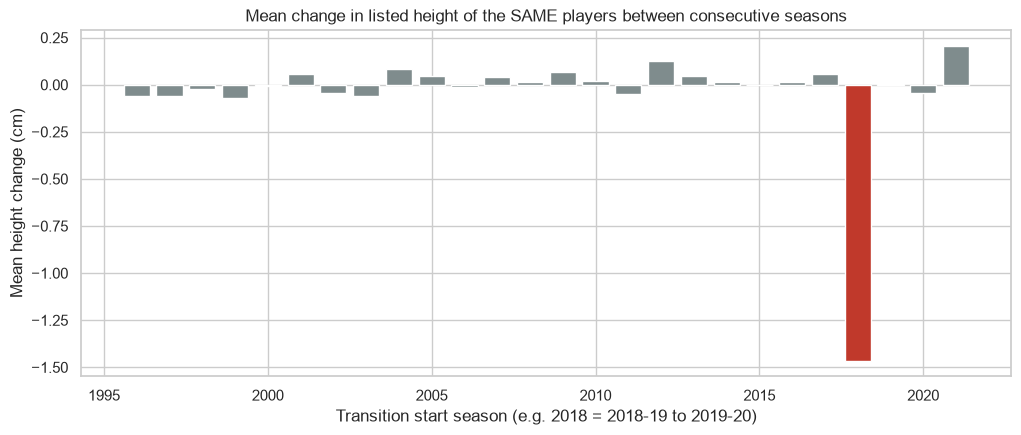

,players,mean_change_cm,median_change_cm
transition_start,,,
2016,388,0.013,0.000
2017,412,0.055,0.000
2018,399,-1.464,-2.540
2019,435,0.006,0.000
2020,445,-0.046,0.000


In [32]:
def height_change_between_consecutive_seasons(df: pd.DataFrame) -> pd.DataFrame:
    """For players present in two consecutive seasons, summarise the change in listed height (cm).

    Only (player_name, season) combinations that are unique are used, so namesakes cannot contaminate the comparison.
    """
    unique_rows = df.drop_duplicates(["player_name", "season"], keep=False)
    rows = []
    for season_start in sorted(unique_rows["season_start"].unique())[:-1]:
        previous = unique_rows[unique_rows["season_start"] == season_start].set_index("player_name")["player_height"]
        following = unique_rows[unique_rows["season_start"] == season_start + 1].set_index("player_name")["player_height"]
        height_difference = (following - previous).dropna()
        rows.append({"transition_start": season_start, "players": len(height_difference),
                     "mean_change_cm": height_difference.mean(), "median_change_cm": height_difference.median()})
    return pd.DataFrame(rows).set_index("transition_start")


height_changes = height_change_between_consecutive_seasons(clean_df)
fig, axis = plt.subplots(figsize=(12, 4.5))
bar_colors = ["#c0392b" if season_year == 2018 else "#7f8c8d" for season_year in height_changes.index]
axis.bar(height_changes.index, height_changes["mean_change_cm"], color=bar_colors)
axis.set_title("Mean change in listed height of the SAME players between consecutive seasons")
axis.set_xlabel("Transition start season (e.g. 2018 = 2018-19 to 2019-20)")
axis.set_ylabel("Mean height change (cm)")
plt.show()
display(height_changes.loc[[2016, 2017, 2018, 2019, 2020]])

**Insight:** for the *same* players, the listed height falls by about 1.5 cm on average (median −2.54 cm = exactly one inch) between 2018-19 and 2019-20, while the other season transitions hover around zero. People do not shrink in one summer – the **measurement convention changed** (my understanding is that the league moved to publishing heights without shoes around that time; this should be verified against an official source). The drop of the league-average height in section 6.3 is therefore an artefact, and **era comparisons of height are unsafe** across that boundary.

### 9.2 Feature engineering (summary)
Engineered in section 4.5: `season_start`, `is_undrafted`, `draft_bucket`, `franchise` (relocation-consistent), `origin_group`, `has_college`, `body_mass_index`, `years_since_draft`, `era`, `height_class`, `age_group`, `scoring_tier`, `is_reliable_sample`. Below: a quick check that the new features carry information.

In [33]:
engineered_check = pd.DataFrame({
    "BMI vs rebounds (Spearman)": [stats.spearmanr(analysis_df["body_mass_index"], analysis_df["reb"])[0]],
    "years_since_draft vs age (Spearman)": [stats.spearmanr(analysis_df.dropna(subset=["years_since_draft"])["years_since_draft"], analysis_df.dropna(subset=["years_since_draft"])["age"])[0]],
    "years_since_draft vs net_rating (Spearman)": [stats.spearmanr(analysis_df.dropna(subset=["years_since_draft"])["years_since_draft"], analysis_df.dropna(subset=["years_since_draft"])["net_rating"])[0]],
}).T.rename(columns={0: "coefficient"})
display(engineered_check)

,coefficient
BMI vs rebounds (Spearman),0.231
years_since_draft vs age (Spearman),0.936
years_since_draft vs net_rating (Spearman),0.231


### 9.3 Hypothesis tests

In [34]:
def cliffs_delta_from_u(u_statistic: float, n_first: int, n_second: int) -> float:
    """Effect size for Mann-Whitney U in [-1, 1]."""
    return 2 * u_statistic / (n_first * n_second) - 1


international_ts = analysis_df.loc[analysis_df["is_international"], "ts_pct"]
domestic_ts = analysis_df.loc[~analysis_df["is_international"], "ts_pct"]
mann_whitney = stats.mannwhitneyu(international_ts, domestic_ts, alternative="two-sided")
height_rebounds = stats.spearmanr(analysis_df["player_height"], analysis_df["reb"])
points_by_bucket = [group["pts"].to_numpy() for _, group in analysis_df.groupby("draft_bucket", observed=True)]
kruskal_result = stats.kruskal(*points_by_bucket)
ts_trend = stats.spearmanr(analysis_df["season_start"], analysis_df["ts_pct"])

hypothesis_results = pd.DataFrame([
    {"hypothesis": "H1: true shooting % differs between international and US players", "test": "Mann-Whitney U",
     "statistic": mann_whitney.statistic, "p_value": mann_whitney.pvalue,
     "effect_size": cliffs_delta_from_u(mann_whitney.statistic, len(international_ts), len(domestic_ts)), "effect_name": "Cliff's delta"},
    {"hypothesis": "H2: taller players grab more rebounds", "test": "Spearman correlation",
     "statistic": height_rebounds.statistic, "p_value": height_rebounds.pvalue, "effect_size": height_rebounds.statistic, "effect_name": "rho"},
    {"hypothesis": "H3: points per game differ across draft buckets", "test": "Kruskal-Wallis",
     "statistic": kruskal_result.statistic, "p_value": kruskal_result.pvalue,
     "effect_size": eta_squared(analysis_df["pts"], analysis_df["draft_bucket"]), "effect_name": "eta squared"},
    {"hypothesis": "H4: shooting efficiency increases over seasons", "test": "Spearman correlation",
     "statistic": ts_trend.statistic, "p_value": ts_trend.pvalue, "effect_size": ts_trend.statistic, "effect_name": "rho"},
])
BONFERRONI_ALPHA = 0.05 / len(hypothesis_results)
hypothesis_results["significant_after_bonferroni"] = hypothesis_results["p_value"] < BONFERRONI_ALPHA
print(f"Bonferroni-corrected alpha = {BONFERRONI_ALPHA:.4f}")
display(hypothesis_results.set_index("hypothesis"))
print("H1 re-checked inside each era (is the international/US gap just an era effect?):")
effect_by_era = {}
for era_label, era_group in analysis_df.groupby("era", observed=True):
    era_international = era_group.loc[era_group["is_international"], "ts_pct"]
    era_domestic = era_group.loc[~era_group["is_international"], "ts_pct"]
    era_u = stats.mannwhitneyu(era_international, era_domestic).statistic
    effect_by_era[era_label] = {
        "n_international": len(era_international),
        "cliffs_delta": cliffs_delta_from_u(era_u, len(era_international), len(era_domestic)),
        "median_ts_gap": era_international.median() - era_domestic.median(),
    }
display(pd.DataFrame(effect_by_era).T)

Bonferroni-corrected alpha = 0.0125


,test,statistic,p_value,effect_size,effect_name,significant_after_bonferroni
hypothesis,,,,,,
H1: true shooting % differs between international and US players,Mann-Whitney U,9623761.500,0.000,0.174,Cliff's delta,True
H2: taller players grab more rebounds,Spearman correlation,0.490,0.000,0.490,rho,True
H3: points per game differ across draft buckets,Kruskal-Wallis,1910.393,0.000,0.199,eta squared,True
H4: shooting efficiency increases over seasons,Spearman correlation,0.309,0.000,0.309,rho,True


H1 re-checked inside each era (is the international/US gap just an era effect?):


,n_international,cliffs_delta,median_ts_gap
1996-2004,318.000,0.039,0.003
2005-2013,638.000,0.129,0.011
2014-2022,892.000,0.129,0.012


**Interpretation**
* All four hypotheses survive the Bonferroni correction (α = 0.0125), but with n ≈ 10,700 almost anything is "significant" – the **effect sizes** matter: H2 is moderate (ρ = 0.49), H3 is large (η² = 0.20), H4 is moderate at row level (ρ = 0.31) and strong on season means (r = 0.88, 9.1), and H1 is small (Cliff's δ = 0.17).
* **H1 is partly confounded by era.** Inside each era the international/US gap in true shooting shrinks (δ ≈ 0.04 in 1996-2004, ≈ 0.13 later) compared with the pooled 0.17, because international players are concentrated in later seasons when everybody shoots more efficiently. A fair comparison must control for era (and minutes).
* **Independence is violated:** the same player appears in many rows, so the p-values are too optimistic; a cluster bootstrap by player would be the right way to quantify uncertainty.

### 9.4 Suggestions for further research

1. **Aging curves:** follow each player across seasons (mixed-effects model with a random intercept per player) instead of comparing different players at different ages.
2. **Causal-style question:** does draft position still predict production after controlling for body size, era and minutes?
3. **Career survival analysis:** time-to-exit from the league by draft bucket and by origin (College vs International), which would also quantify survivorship bias.
4. **Recover positions:** cluster players using height, weight, rebounds, assists and usage (k-means / Gaussian mixture) and compare the clusters with official positions.
5. **The three-point era:** merge shot-level data to test whether the rise in true shooting is explained by shot selection.
6. **Verify the height convention change** against official NBA measurement announcements and rescale heights to a common convention.
7. **Prediction with honest validation:** model next-season points from this-season stats with player-grouped cross-validation and a final time-based test set.